In [1]:
# ============================================================
# STEP 1 — ERROR ANALYSIS SETUP
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/mnt/c/liverCTSegmentation")

SPLIT_DIR = PROJECT_DIR / "outputs" / "splits"
CHECKPOINT_DIR = PROJECT_DIR / "outputs" / "checkpoints"
ANALYSIS_DIR = PROJECT_DIR / "outputs" / "analysis"

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Load train / validation / test splits
# ------------------------------------------------------------

train_csv = SPLIT_DIR / "train.csv"
val_csv = SPLIT_DIR / "validation.csv"
test_csv = SPLIT_DIR / "test.csv"

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

print("\nDataset sizes")
print("-" * 40)
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

# ------------------------------------------------------------
# Original U-Net checkpoint
# ------------------------------------------------------------

BEST_CHECKPOINT = CHECKPOINT_DIR / "baseline_unet_best_recovered.keras"

print("\nCheckpoint:")
print(BEST_CHECKPOINT)
print("Exists:", BEST_CHECKPOINT.exists())

# ------------------------------------------------------------
# Image configuration
# ------------------------------------------------------------

IMG_HEIGHT = 128
IMG_WIDTH = 128

print("\nImage size:", IMG_HEIGHT, "x", IMG_WIDTH)

2026-10-07 12:00:58.152465: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-07 12:00:58.439707: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791374458.573922     790 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791374458.607783     790 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-07 12:00:58.844575: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

TensorFlow version: 2.18.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Dataset sizes
----------------------------------------
Train      : 39677
Validation : 8960
Test       : 10001

Checkpoint:
/mnt/c/liverCTSegmentation/outputs/checkpoints/baseline_unet_best_recovered.keras
Exists: True

Image size: 128 x 128


In [4]:
# ============================================================
# MEMORY-SAFE STREAMING INFERENCE + ERROR ANALYSIS
# ============================================================

BATCH_SIZE = 8

def create_dataset(df, batch_size=BATCH_SIZE):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            df["image_path"].astype(str).values,
            df["mask_path"].astype(str).values
        )
    )

    dataset = dataset.map(
        load_image_mask,
        num_parallel_calls=1
    )

    dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(1)

    return dataset


# ------------------------------------------------------------
# Streaming metric calculation
# ------------------------------------------------------------

def calculate_batch_metrics(y_true, y_pred, smooth=1e-7):

    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    results = []

    for i in range(len(y_true)):

        gt = y_true[i]
        pred = y_pred[i]

        tp = np.logical_and(gt, pred).sum()
        tn = np.logical_and(~gt, ~pred).sum()
        fp = np.logical_and(~gt, pred).sum()
        fn = np.logical_and(gt, ~pred).sum()

        dice = (
            2.0 * tp + smooth
        ) / (
            2.0 * tp + fp + fn + smooth
        )

        iou = (
            tp + smooth
        ) / (
            tp + fp + fn + smooth
        )

        precision = (
            tp + smooth
        ) / (
            tp + fp + smooth
        )

        recall = (
            tp + smooth
        ) / (
            tp + fn + smooth
        )

        accuracy = (
            tp + tn
        ) / (
            tp + tn + fp + fn
        )

        results.append({
            "dice": dice,
            "iou": iou,
            "precision": precision,
            "recall": recall,
            "accuracy": accuracy,

            "tp": int(tp),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),

            "gt_area": int(gt.sum()),
            "pred_area": int(pred.sum())
        })

    return results


# ============================================================
# RUN TEST ERROR ANALYSIS
# ============================================================

print("\nRunning memory-safe test inference...")

test_dataset = create_dataset(
    test_df,
    batch_size=BATCH_SIZE
)

slice_results = []

start_time = time.time()

sample_index = 0

for batch_number, (batch_imgs, batch_masks) in enumerate(
    test_dataset
):

    # --------------------------------------------------------
    # GPU inference for current batch only
    # --------------------------------------------------------

    preds = predict_step(batch_imgs)

    preds = preds.numpy()

    # Convert to binary uint8
    pred_binary = (
        preds[..., 0] >= THRESHOLD
    ).astype(np.uint8)

    true_binary = (
        batch_masks.numpy()[..., 0] >= 0.5
    ).astype(np.uint8)

    # --------------------------------------------------------
    # Calculate metrics immediately
    # --------------------------------------------------------

    batch_results = calculate_batch_metrics(
        true_binary,
        pred_binary
    )

    # --------------------------------------------------------
    # Add file information
    # --------------------------------------------------------

    for j, metrics in enumerate(batch_results):

        idx = sample_index + j

        slice_results.append({

            "index": idx,

            "image_path":
                test_df.iloc[idx]["image_path"],

            "mask_path":
                test_df.iloc[idx]["mask_path"],

            **metrics

        })

    sample_index += len(batch_results)

    # --------------------------------------------------------
    # Release batch memory
    # --------------------------------------------------------

    del batch_imgs
    del batch_masks
    del preds
    del pred_binary
    del true_binary

    if batch_number % 100 == 0:

        gc.collect()

        print(
            f"Processed "
            f"{sample_index}/{len(test_df)} "
            f"test slices"
        )


elapsed = time.time() - start_time

print("\nInference complete!")

print(
    f"Total samples : {sample_index}"
)

print(
    f"Time          : {elapsed:.2f} seconds"
)

print(
    f"FPS           : "
    f"{sample_index / elapsed:.2f}"
)


# ============================================================
# CREATE RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(slice_results)

results_df["gt_nonempty"] = (
    results_df["gt_area"] > 0
)

nonempty_df = results_df[
    results_df["gt_nonempty"]
].copy()


# ============================================================
# TEST SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("BASELINE U-NET — TEST ERROR ANALYSIS")
print("=" * 60)

print(
    f"Total slices       : {len(results_df)}"
)

print(
    f"Non-empty slices   : {len(nonempty_df)}"
)

print(
    f"Empty slices       : "
    f"{len(results_df) - len(nonempty_df)}"
)

print("\n--- Non-Empty Liver Slices ---")

print(
    "Dice      :",
    round(nonempty_df["dice"].mean(), 4)
)

print(
    "IoU       :",
    round(nonempty_df["iou"].mean(), 4)
)

print(
    "Precision :",
    round(nonempty_df["precision"].mean(), 4)
)

print(
    "Recall    :",
    round(nonempty_df["recall"].mean(), 4)
)

print(
    "Accuracy  :",
    round(nonempty_df["accuracy"].mean(), 4)
)


# ============================================================
# SAVE RESULTS
# ============================================================

output_file = (
    ANALYSIS_DIR /
    "baseline_unet_test_per_slice_metrics.csv"
)

results_df.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file)


# ============================================================
# CLEANUP
# ============================================================

del test_dataset
del results_df
del nonempty_df
gc.collect()

print("\nMemory cleanup completed.")


Running memory-safe test inference...
Processed 8/10001 test slices
Processed 808/10001 test slices
Processed 1608/10001 test slices
Processed 2408/10001 test slices
Processed 3208/10001 test slices
Processed 4008/10001 test slices
Processed 4808/10001 test slices
Processed 5608/10001 test slices
Processed 6408/10001 test slices
Processed 7208/10001 test slices
Processed 8008/10001 test slices
Processed 8808/10001 test slices
Processed 9608/10001 test slices


2026-10-07 12:05:57.603366: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Inference complete!
Total samples : 10001
Time          : 143.48 seconds
FPS           : 69.70

BASELINE U-NET — TEST ERROR ANALYSIS
Total slices       : 10001
Non-empty slices   : 3216
Empty slices       : 6785

--- Non-Empty Liver Slices ---
Dice      : 0.4727
IoU       : 0.4156
Precision : 0.682
Recall    : 0.5895
Accuracy  : 0.9719

Saved:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_test_per_slice_metrics.csv

Memory cleanup completed.


LIVER CT SEGMENTATION — BASELINE U-NET ERROR ANALYSIS
TensorFlow version: 2.18.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU memory growth enabled.

Project: /mnt/c/liverCTSegmentation
Checkpoint: /mnt/c/liverCTSegmentation/outputs/checkpoints/baseline_unet_best_recovered.keras
Metrics CSV: /mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_test_per_slice_metrics.csv

LOADING DATA SPLITS
Train      : 39677
Validation : 8960
Test       : 10001

LOADING SAVED TEST METRICS
Rows loaded: 10001

Test slice classification
--------------------------------------------------
Total slices: 10001
Non-empty: 3216
Empty: 6785
Non-empty percentage: 32.16 %
Empty percentage: 67.84 %

BASELINE U-NET — TEST RESULTS

--- Overall Test ---
Dice        : 0.8053
Iou         : 0.7870
Precision   : 0.8727
Recall      : 0.8680
Accuracy    : 0.9909

--- Non-Empty Test Slices ---
Dice        : 0.4727
Iou         : 0.4156
Precision   : 0.6820
Recall      : 0.5895
Accuracy   

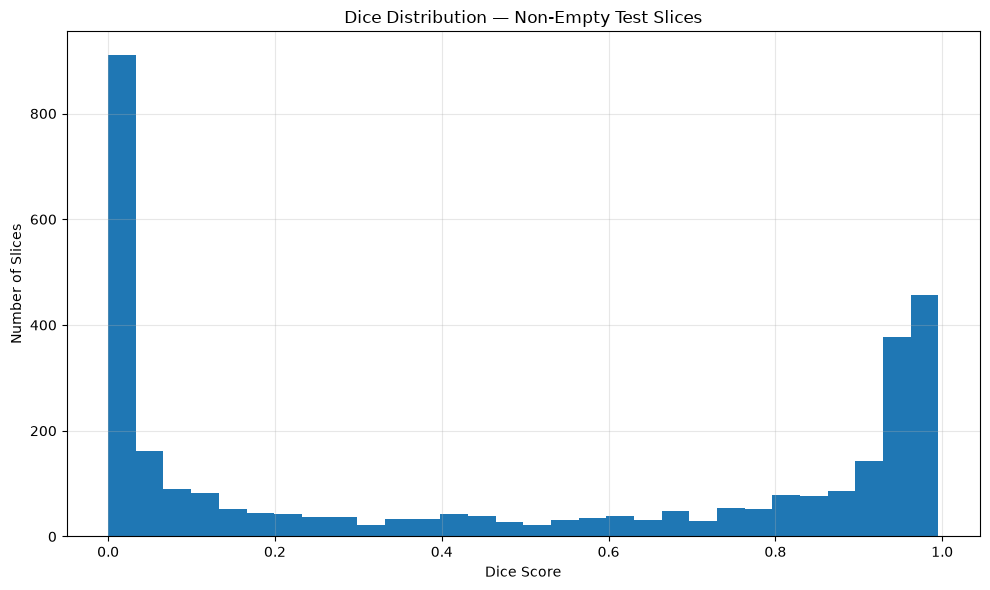

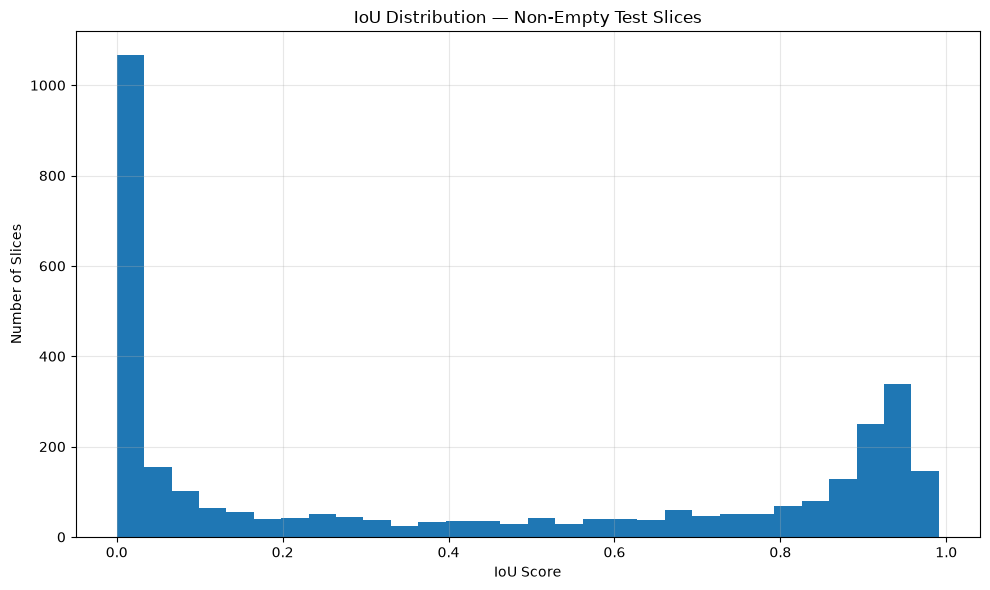

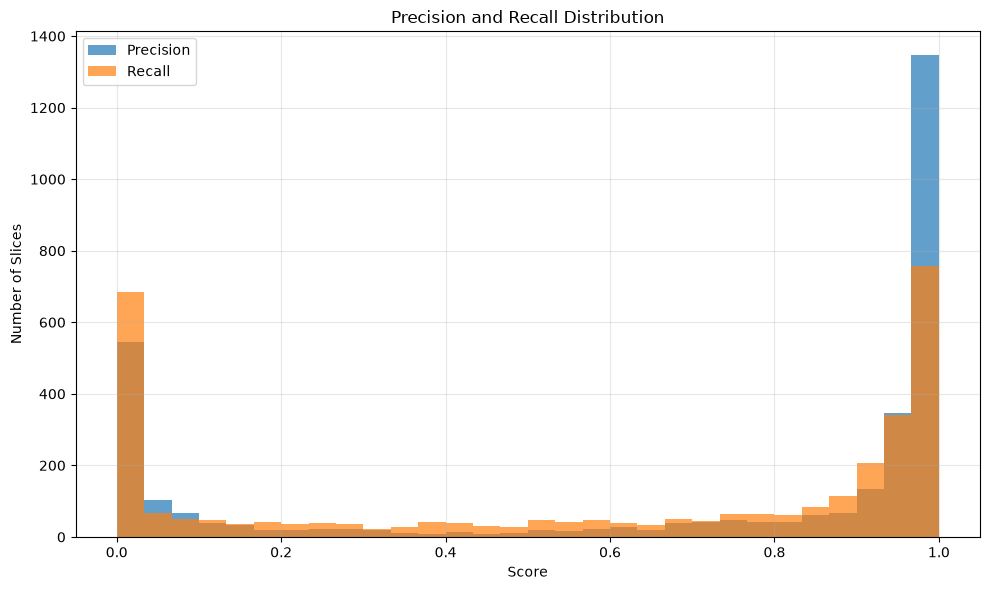


LIVER SIZE ANALYSIS
               size_group  slices  mean_dice  median_dice  mean_iou  \
0            Tiny (1-100)    1032     0.1957       0.0286    0.1508   
1         Small (101-500)     931     0.5163       0.5353    0.4477   
2       Medium (501-1000)     528     0.5605       0.6802    0.5018   
3       Large (1001-2000)     523     0.7736       0.9372    0.7138   
4  Very Large (2001-4000)     202     0.6783       0.9223    0.6222   

   mean_precision  mean_recall  
0          0.3904       0.5433  
1          0.7334       0.5679  
2          0.7964       0.5387  
3          0.9408       0.7482  
4          0.9662       0.6475  


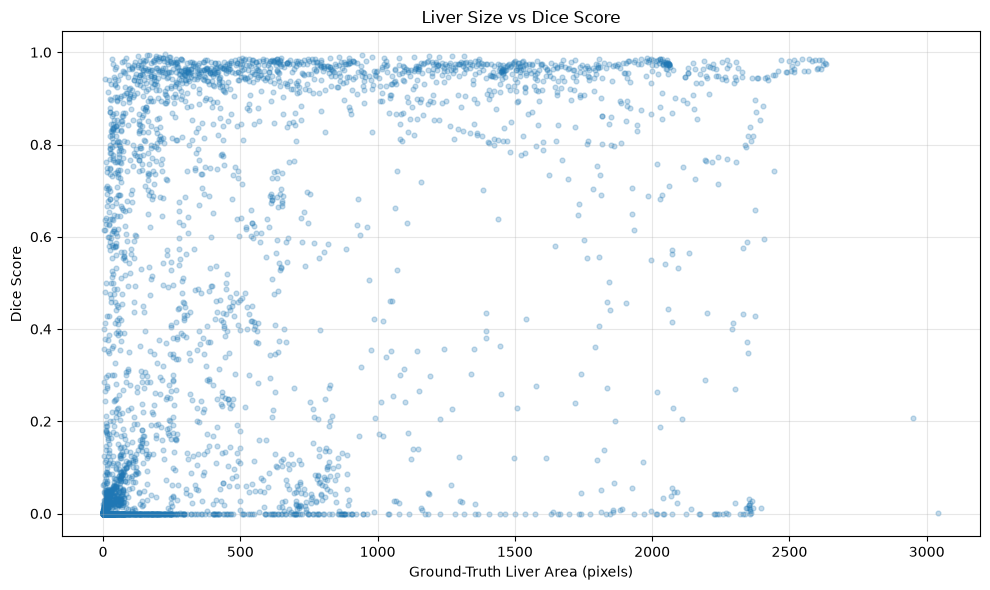


FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
                  Metric      Mean   Median
0  False Positive Pixels    257.29     24.0
1  False Negative Pixels    202.46     44.0
2   True Positive Pixels    383.12     86.5
3   True Negative Pixels  15541.13  15739.5


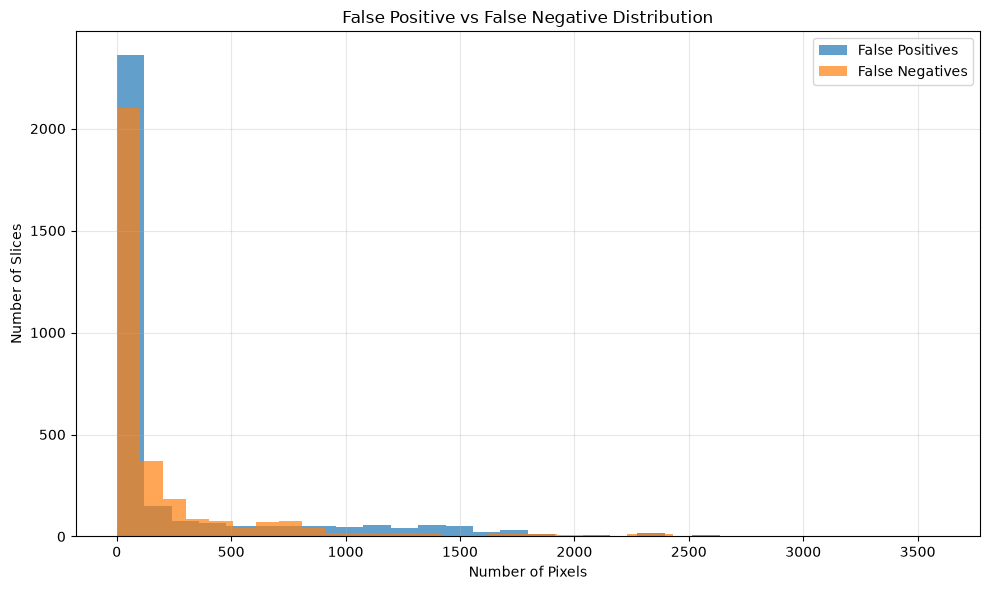


20 WORST NON-EMPTY TEST SLICES
 index  gt_area  pred_area  dice  iou  precision  recall   fp   fn
  6646     2355          0   0.0  0.0        1.0     0.0    0 2355
  6642     2338          0   0.0  0.0        1.0     0.0    0 2338
   444     2332          0   0.0  0.0        1.0     0.0    0 2332
  6641     2321          0   0.0  0.0        1.0     0.0    0 2321
   445     2275          0   0.0  0.0        1.0     0.0    0 2275
  6664     2258          0   0.0  0.0        1.0     0.0    0 2258
  6665     2245          0   0.0  0.0        1.0     0.0    0 2245
   446     2235          0   0.0  0.0        1.0     0.0    0 2235
  6666     2230          0   0.0  0.0        1.0     0.0    0 2230
  6667     2225          0   0.0  0.0        1.0     0.0    0 2225
   447     2176          0   0.0  0.0        1.0     0.0    0 2176
  5675     2171          0   0.0  0.0        1.0     0.0    0 2171
   448     2123          0   0.0  0.0        1.0     0.0    0 2123
   449     2073          0   0

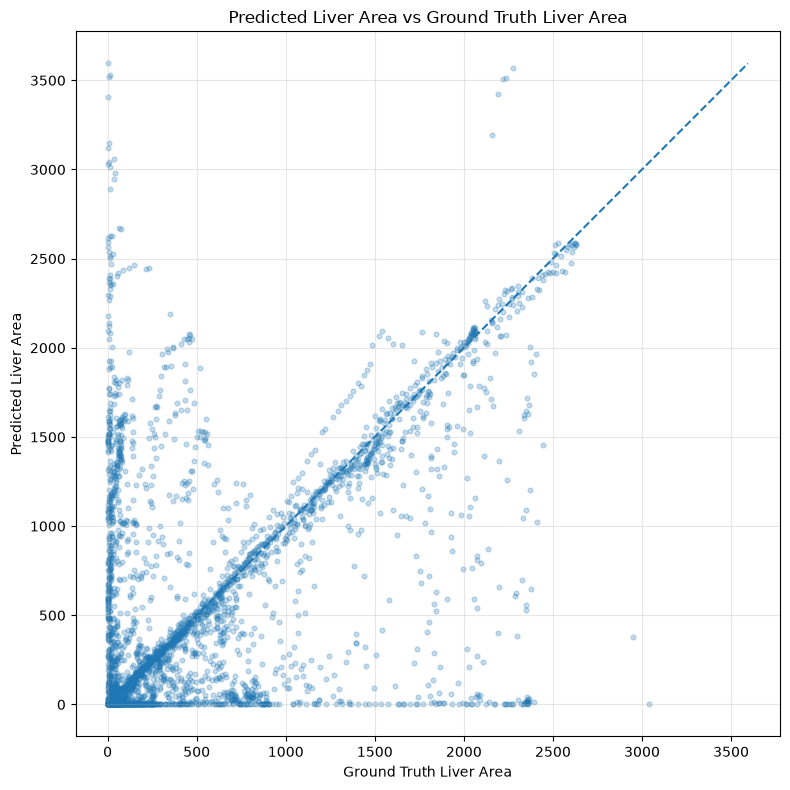


AREA ERROR STATISTICS
         gt_area  pred_area  area_error  relative_area_error       dice
count  3216.0000  3216.0000   3216.0000            3216.0000  3216.0000
mean    585.5793   640.4179     54.8386              21.1876     0.4727
std     671.6234   695.7054    699.5946             131.5364     0.4123
min       1.0000     0.0000  -3038.0000              -1.0000     0.0000
25%      60.0000    53.7500   -126.2500              -0.6162     0.0208
50%     294.5000   357.0000     -8.0000              -0.0265     0.4475
75%     872.2500  1116.2500     82.5000               0.5482     0.9344
max    3042.0000  3595.0000   3593.0000            3122.0000     0.9956

LOADING MODEL FOR QUALITATIVE VISUALIZATION
Model loaded: Baseline_UNet
Parameters: 31030593

WORST-PERFORMING EXAMPLES


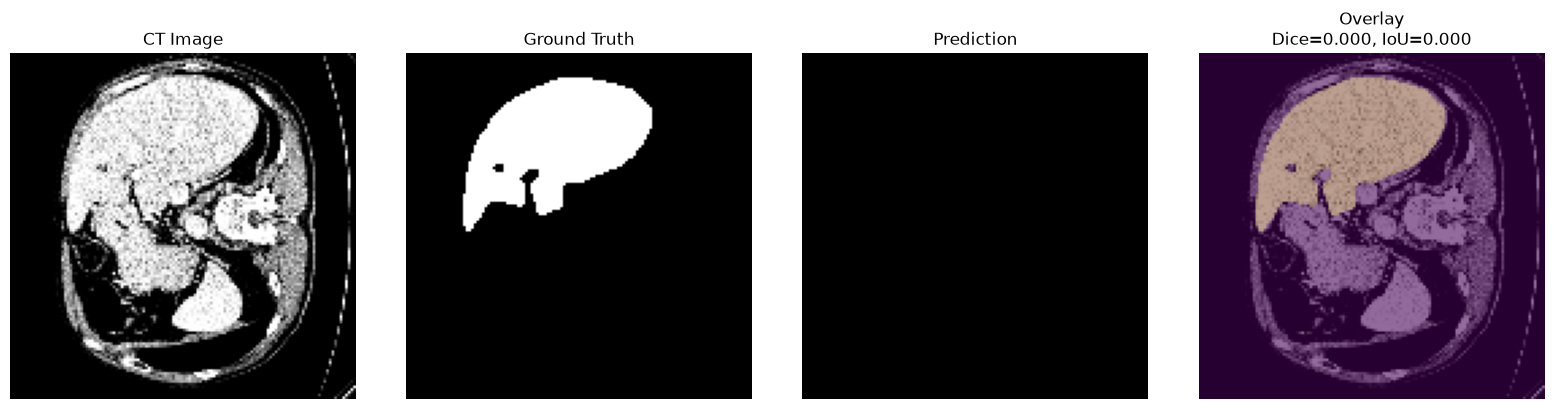

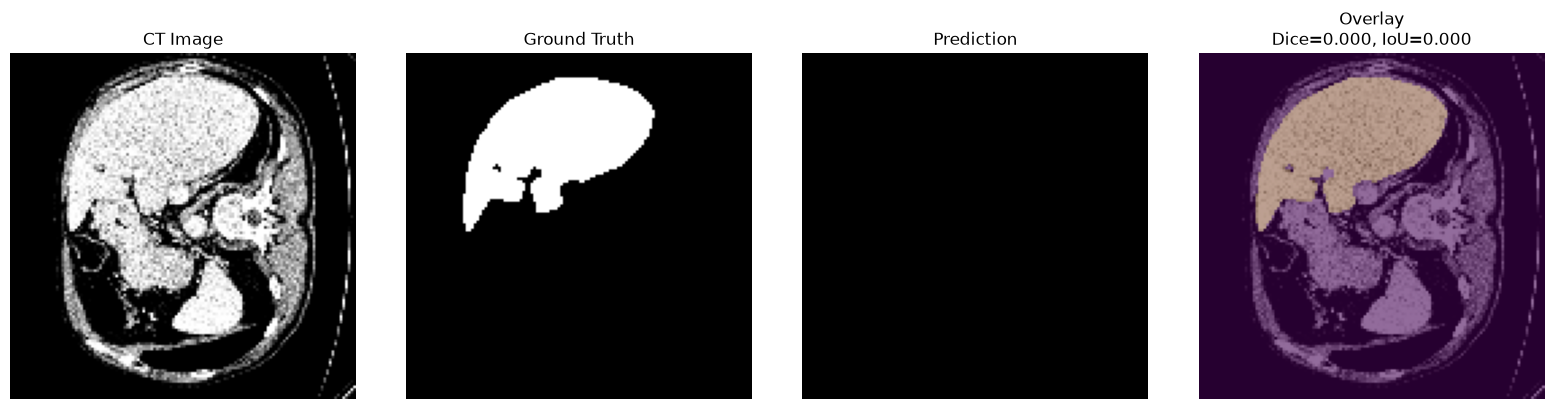

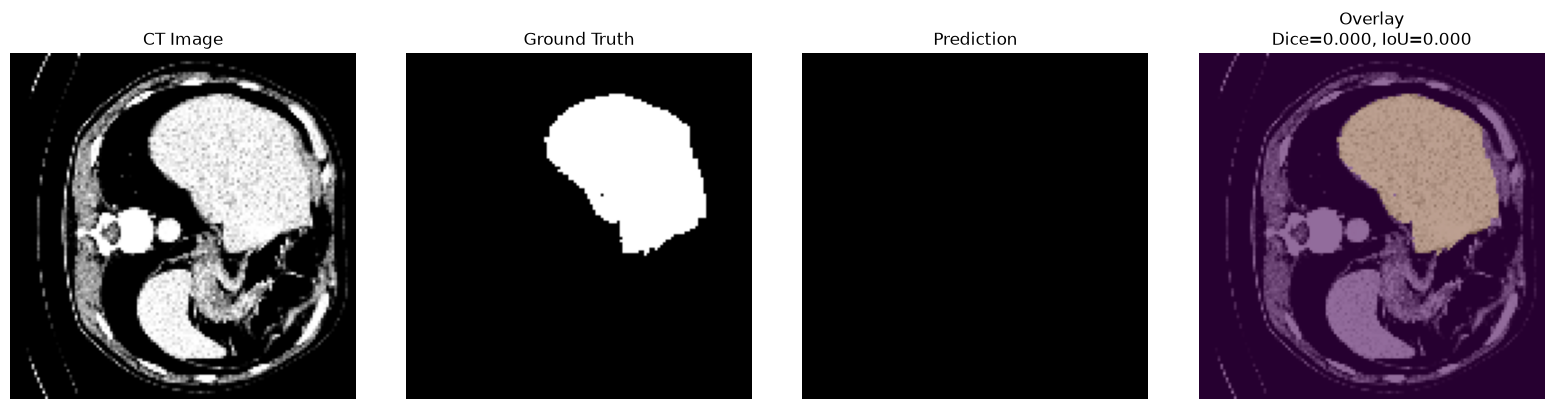

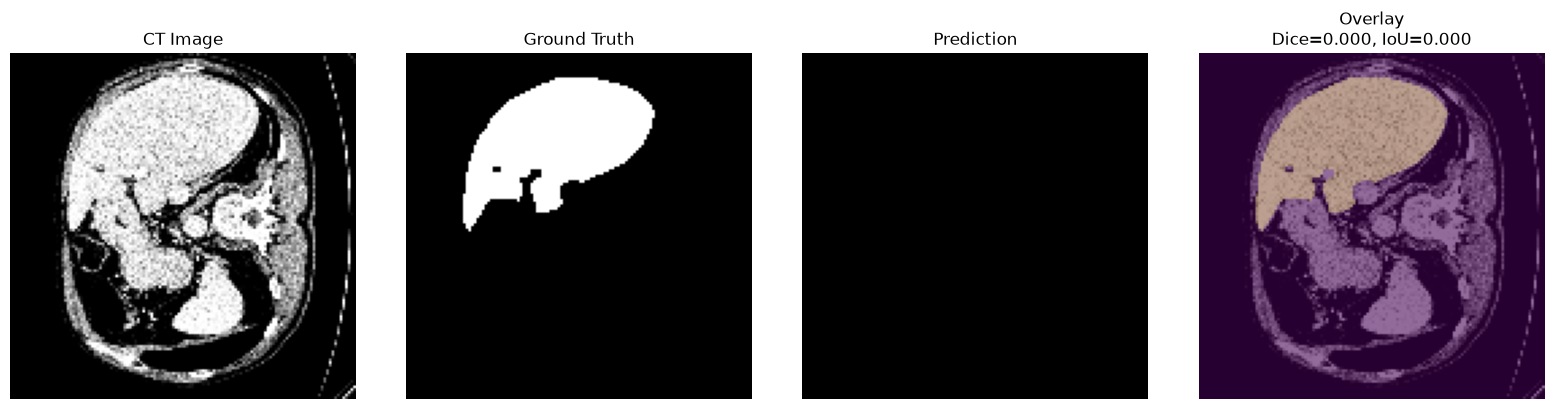

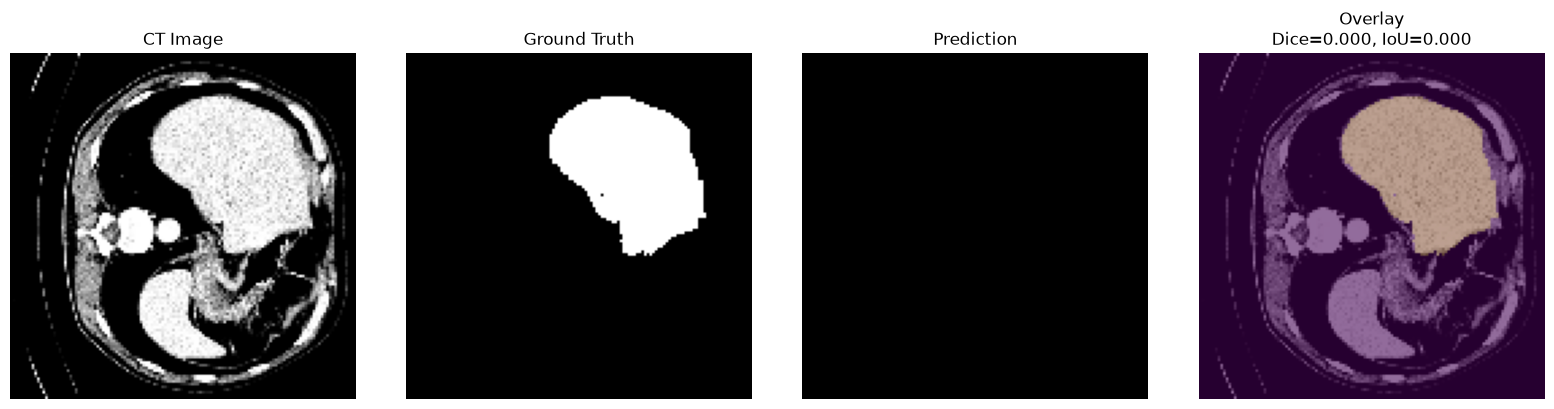


BEST-PERFORMING EXAMPLES


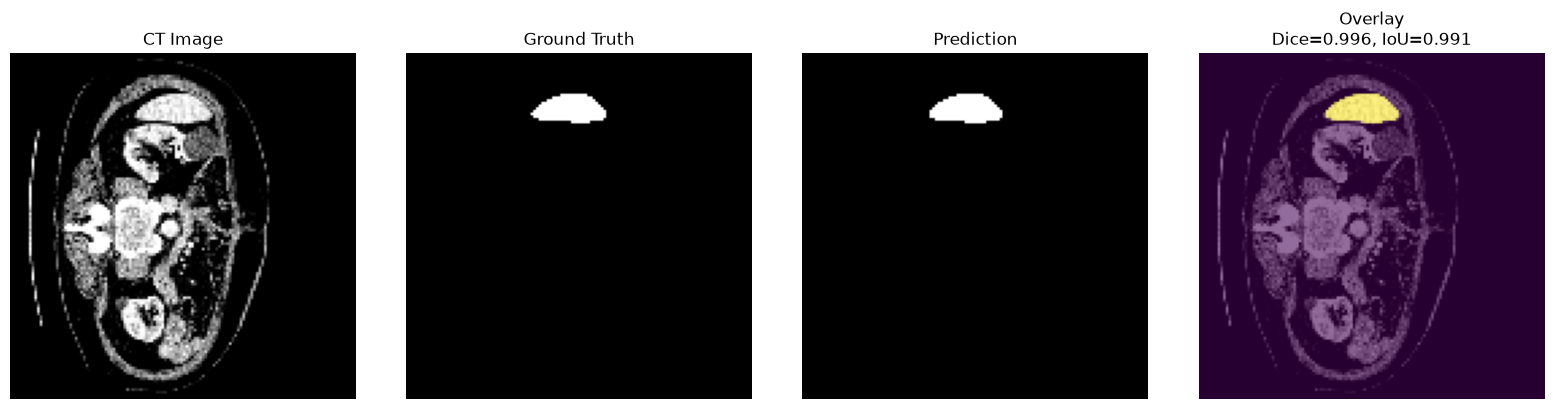

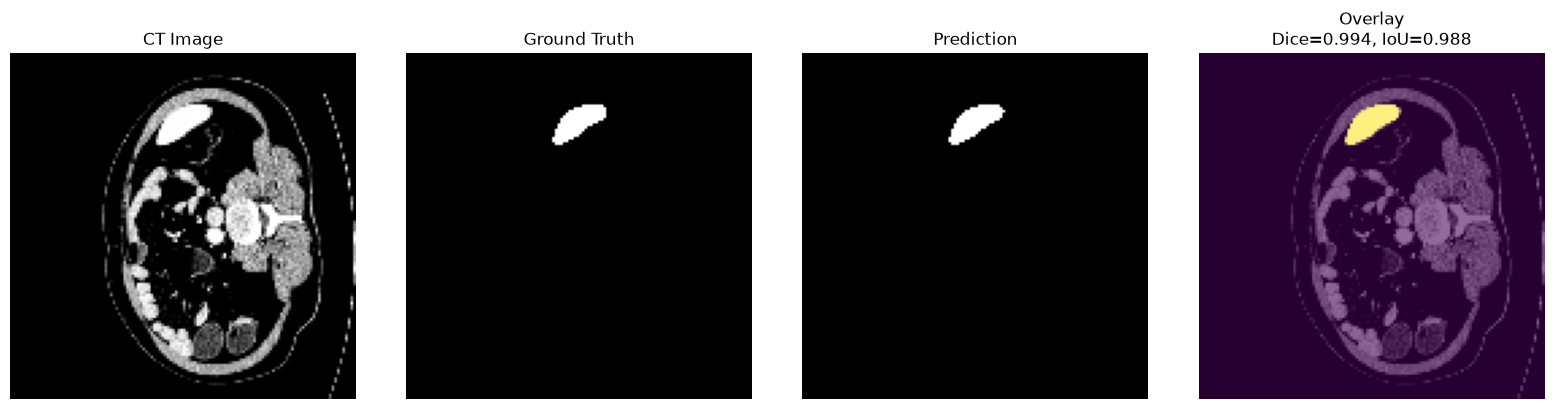

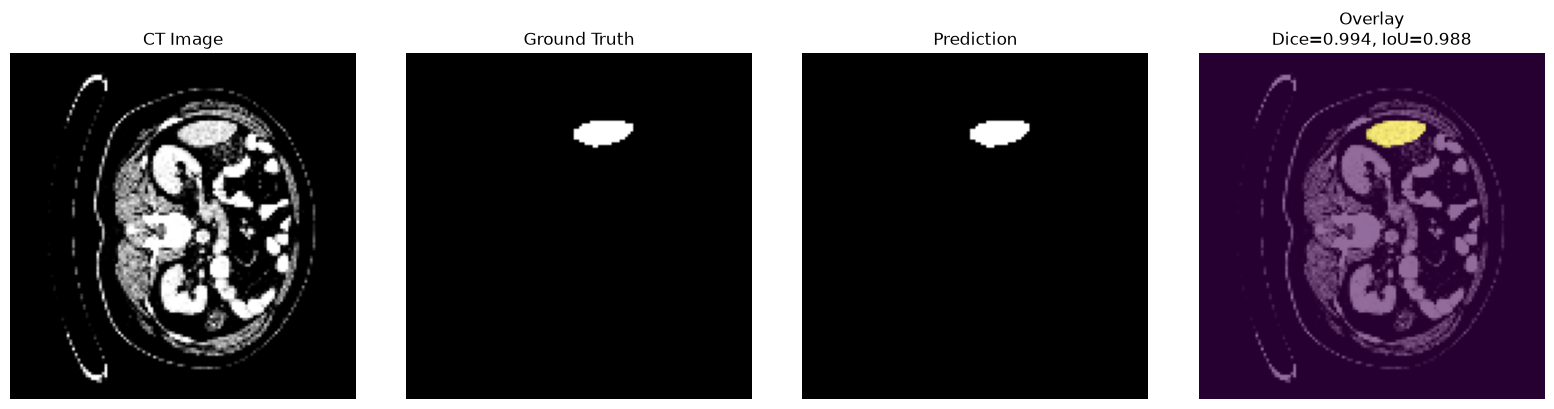

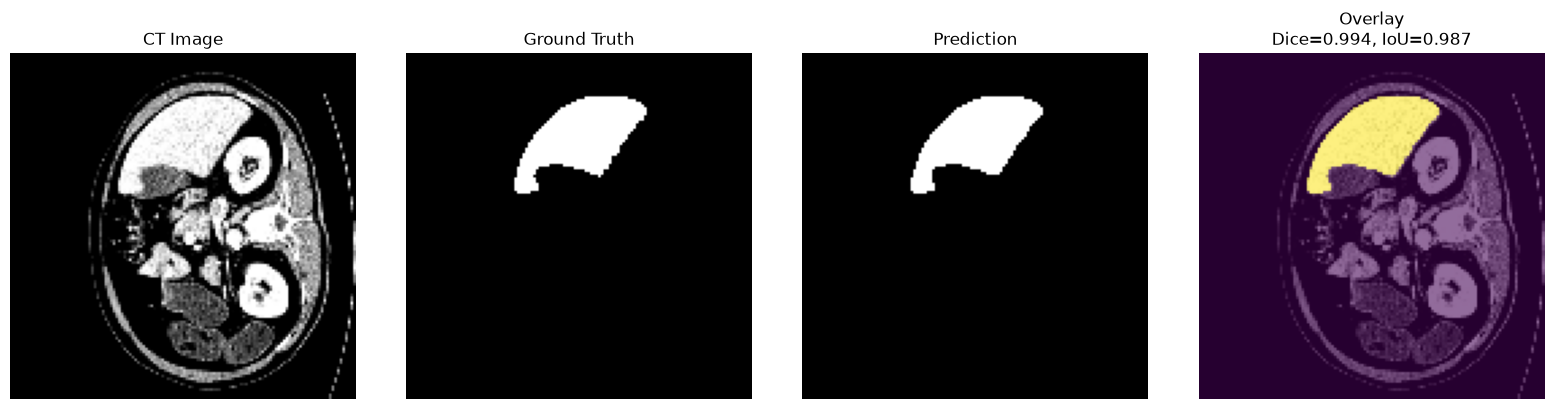

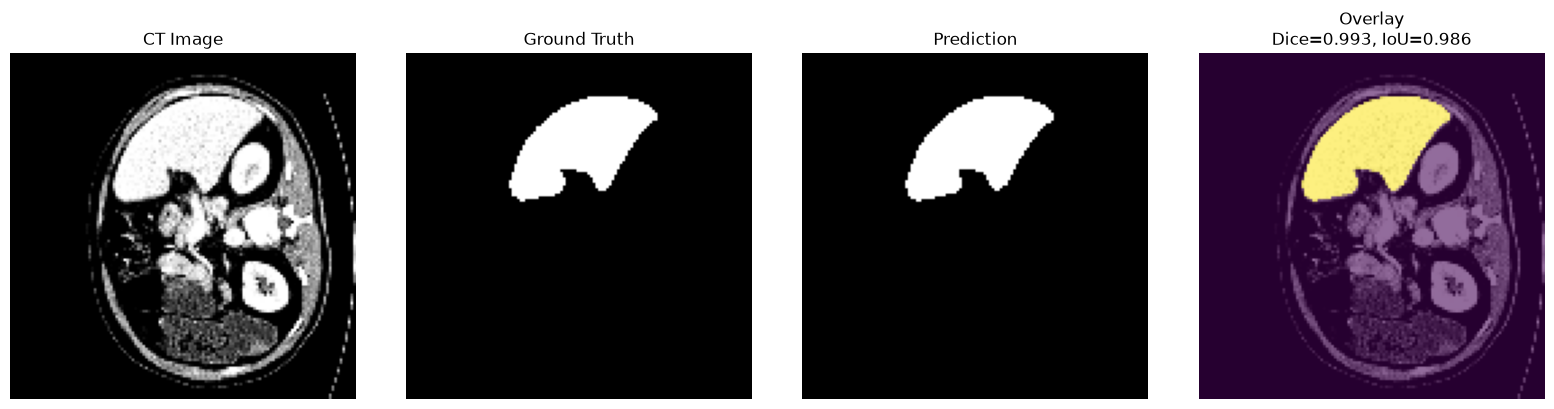


MISSED LIVER EXAMPLES


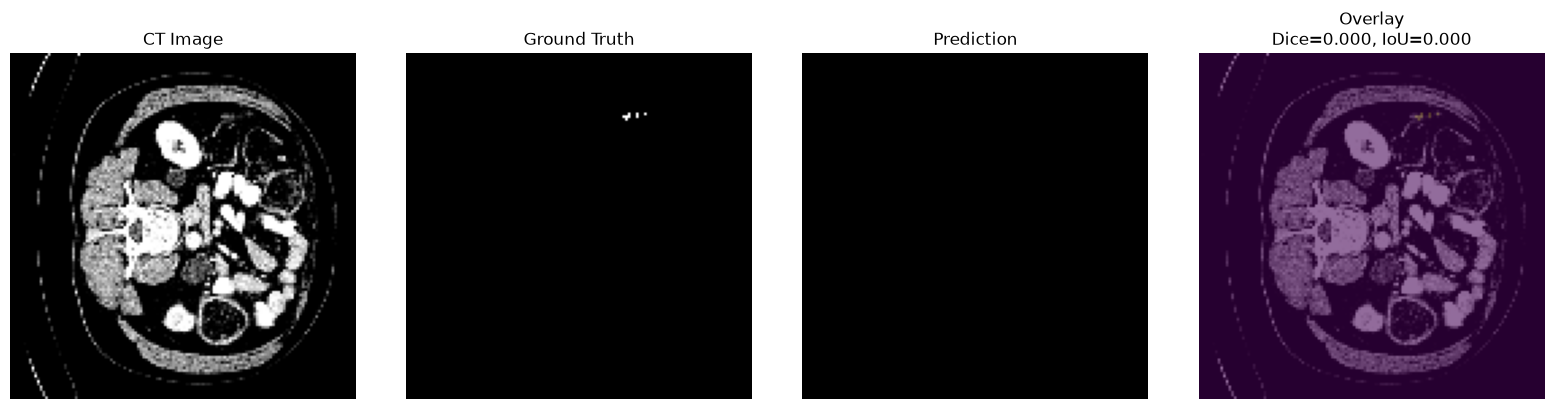

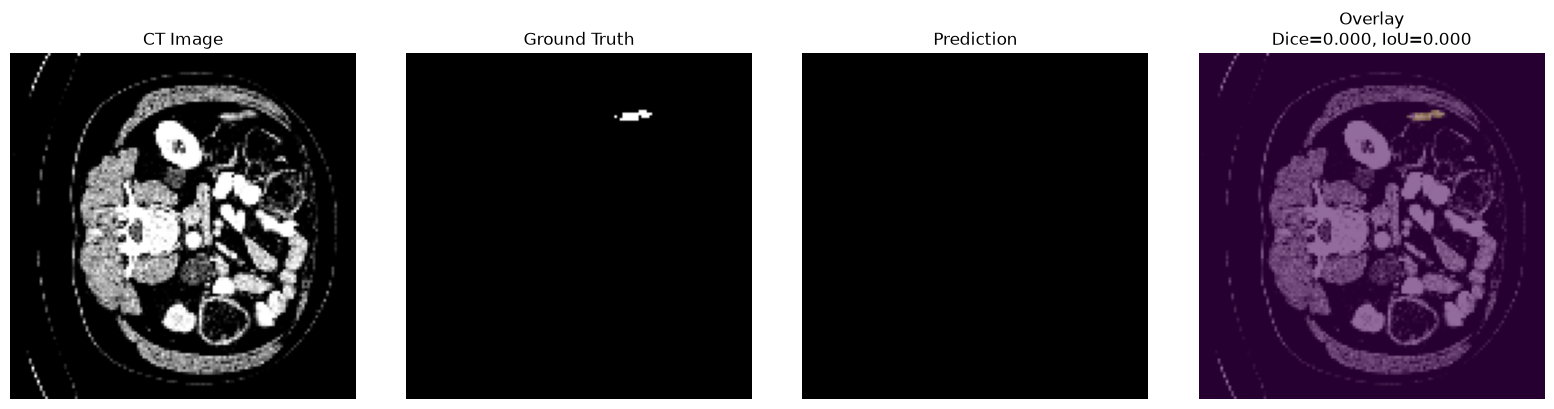

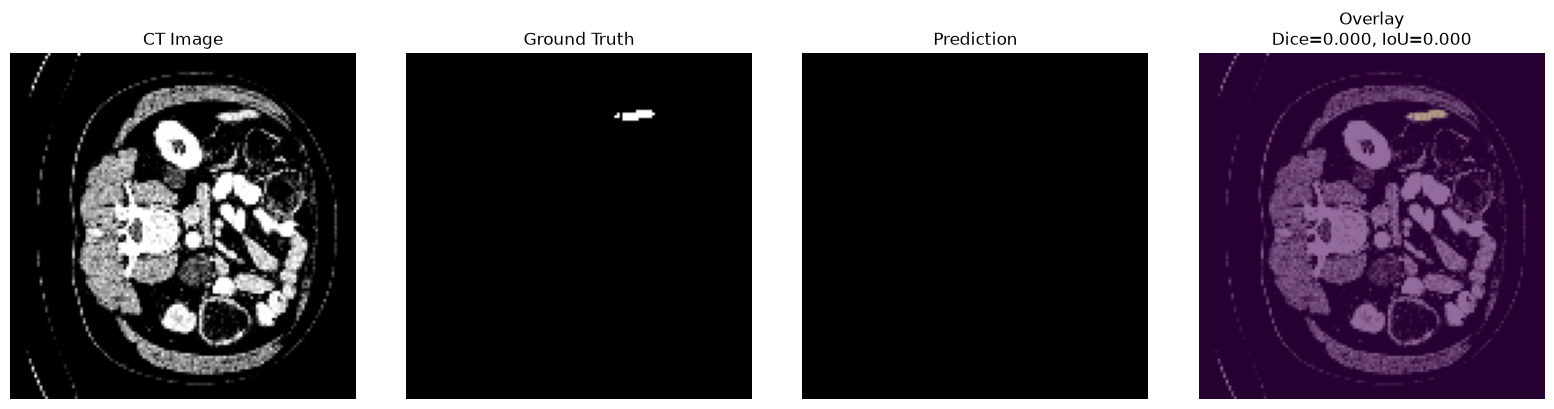

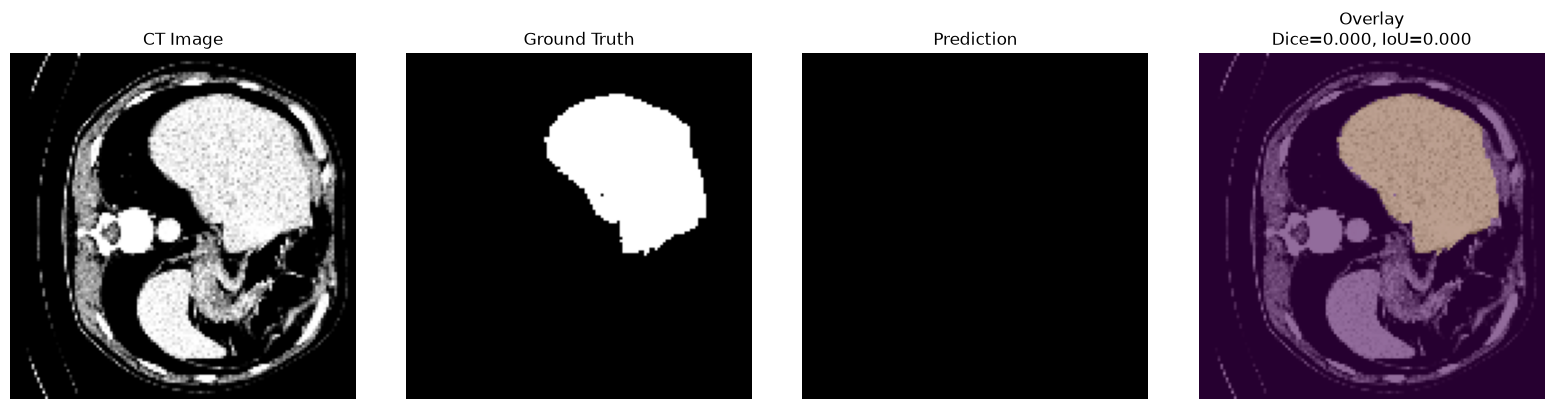

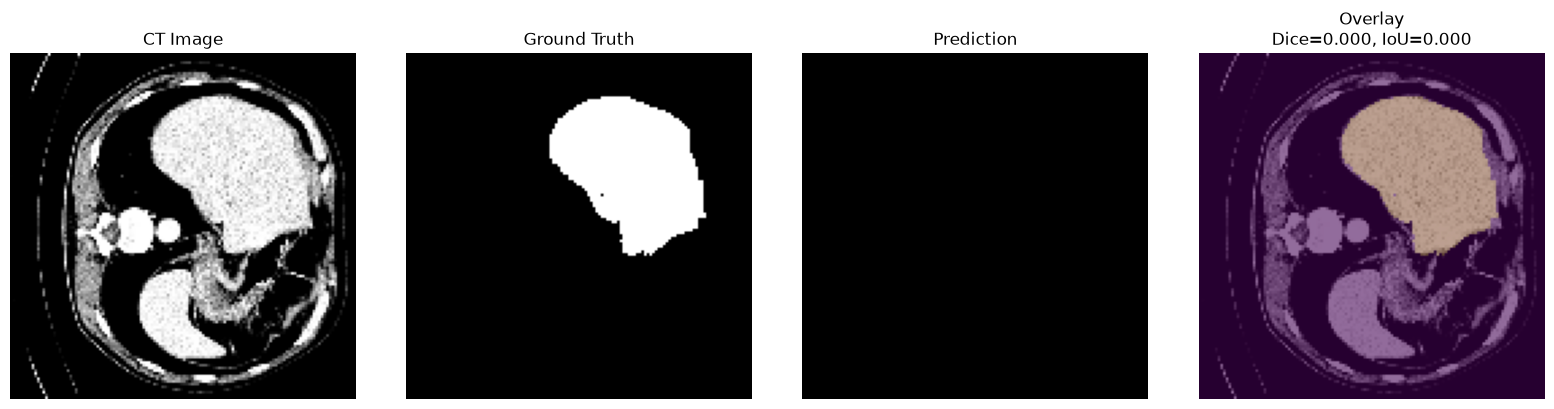


EMPTY-SLICE FALSE POSITIVE EXAMPLES


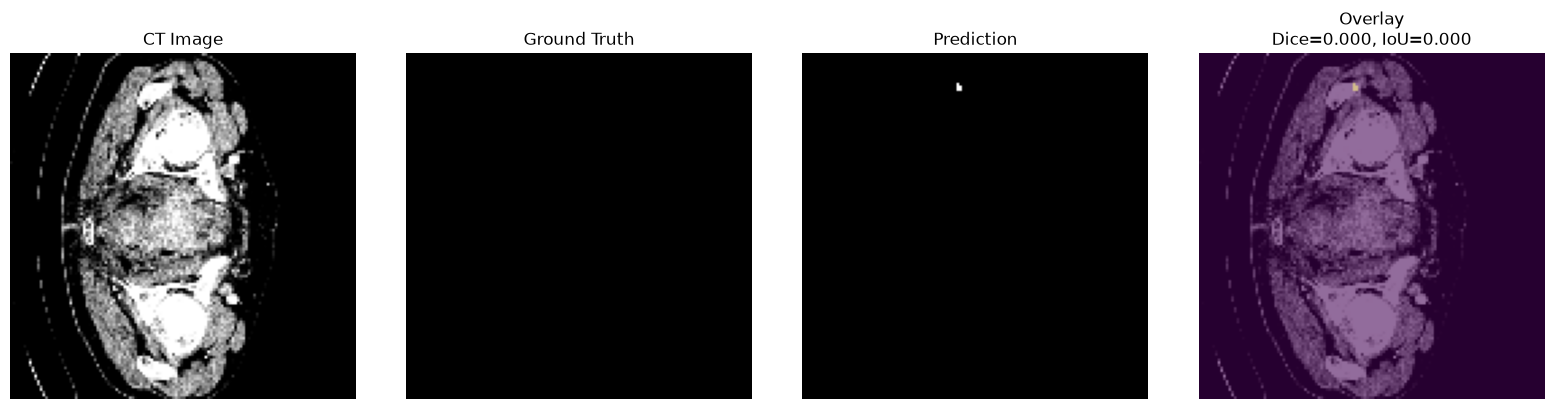

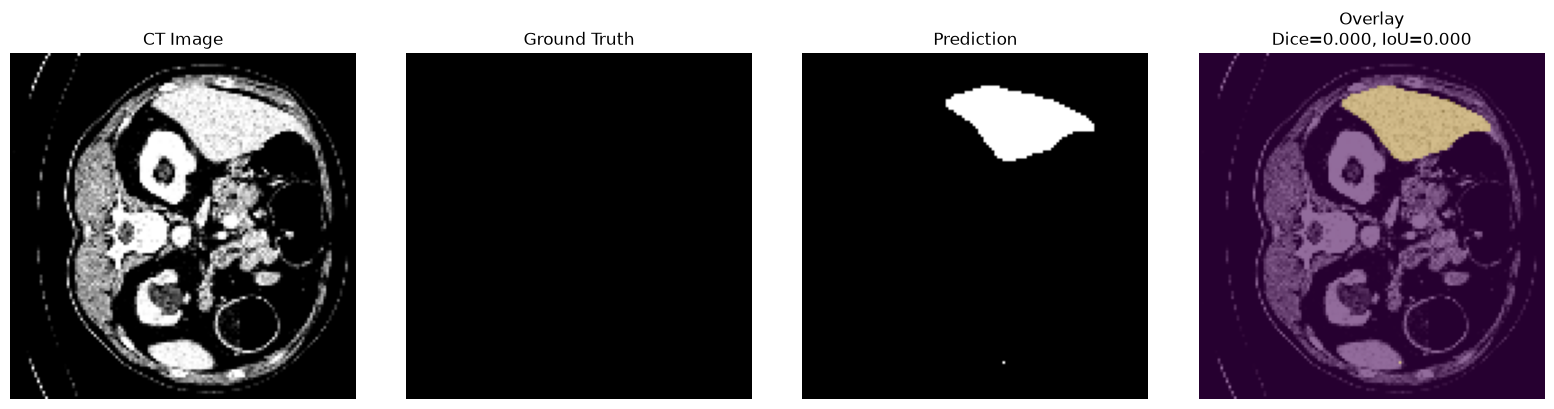

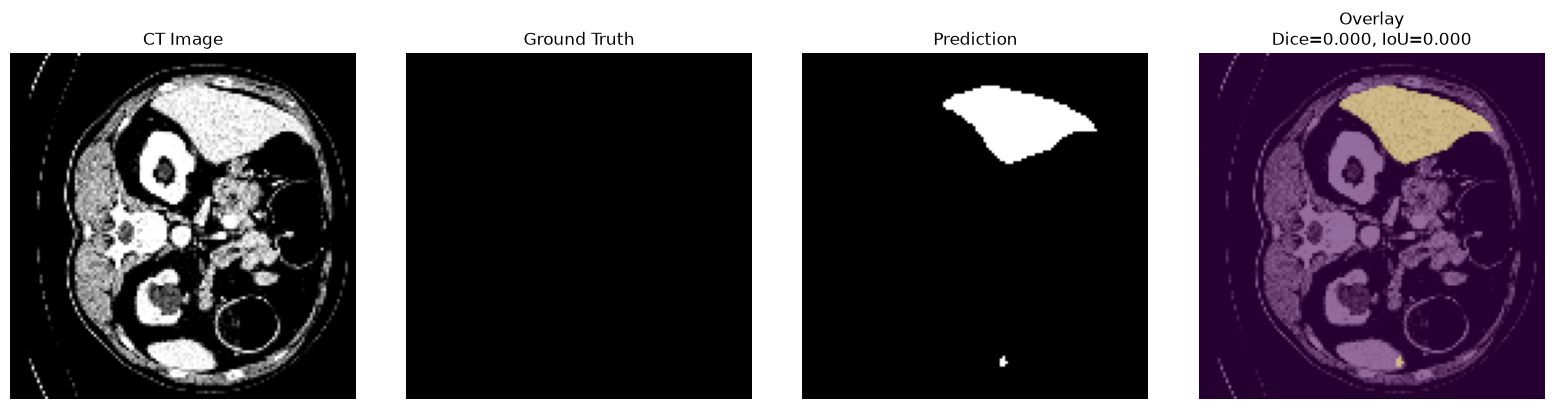

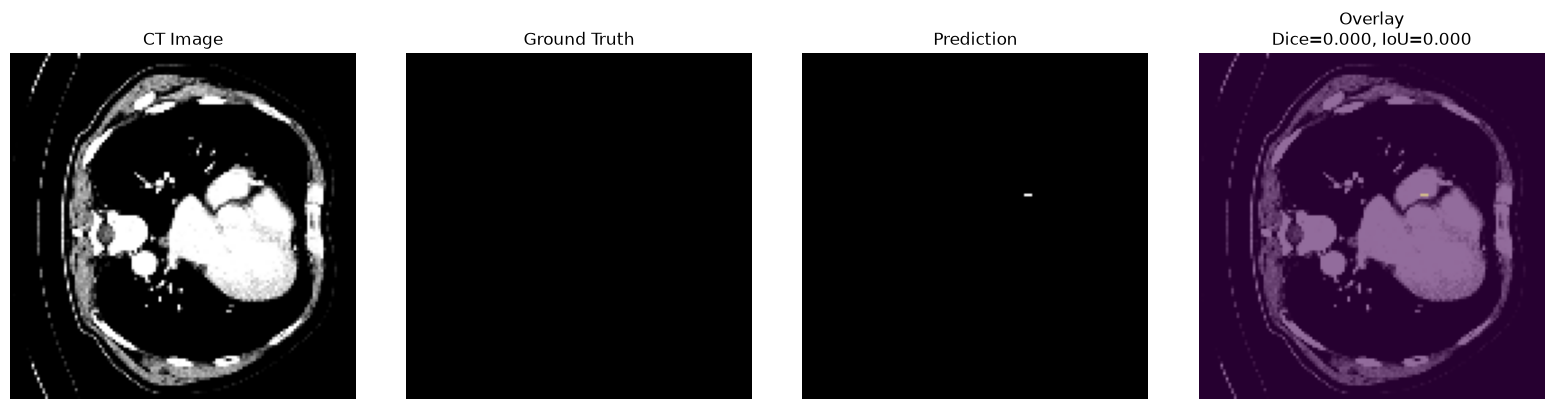

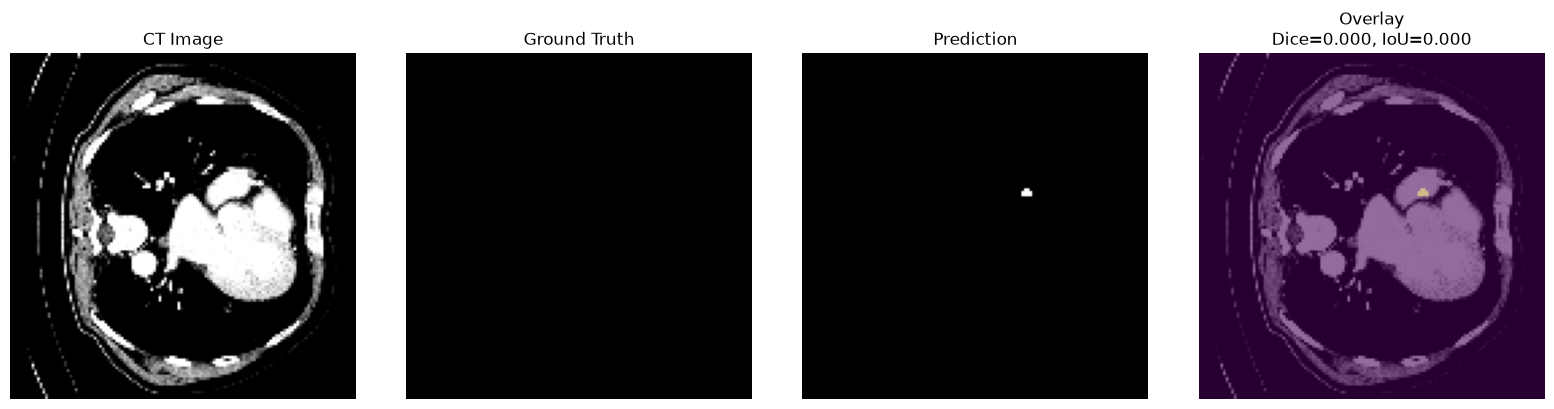


MEMORY-SAFE VALIDATION ANALYSIS

Validation inference complete.
Validation slices: 8960
Validation non-empty: 2819
Time: 298.36 seconds

VALIDATION VS TEST — NON-EMPTY SLICES
           Metric  Validation Non-Empty  Test Non-Empty  Difference
0            Dice                0.6303          0.4727     -0.1576
1             IoU                0.5678          0.4156     -0.1523
2       Precision                0.7612          0.6820     -0.0791
3          Recall                0.7139          0.5895     -0.1244
4  Pixel Accuracy                0.9752          0.9719     -0.0033

SAVING ERROR-ANALYSIS RESULTS
All analysis files saved to:
/mnt/c/liverCTSegmentation/outputs/analysis


FINAL BASELINE U-NET ERROR ANALYSIS SUMMARY

MODEL
----------------------------------------
Model: Baseline_UNet
Parameters: 31030593

TEST DATA
----------------------------------------
Total slices: 10001
Non-empty slices: 3216
Empty slices: 6785

NON-EMPTY TEST PERFORMANCE
----------------------------------

In [5]:
# ============================================================
# 07_UNET_ERROR_ANALYSIS
# COMPLETE STEP 7 — BASELINE U-NET ERROR ANALYSIS
#
# IMPORTANT:
# Test inference has ALREADY been completed.
#
# This cell:
#   1. Loads saved per-slice test metrics
#   2. Performs test-set error analysis
#   3. Analyzes Dice / IoU distributions
#   4. Performs liver-size analysis
#   5. Performs FP / FN analysis
#   6. Finds worst / best cases
#   7. Finds missed-liver cases
#   8. Finds empty-slice false positives
#   9. Performs Dice-category analysis
#  10. Performs predicted-vs-GT area analysis
#  11. Loads the model only for qualitative visualization
#  12. Runs validation analysis in a MEMORY-SAFE way
#  13. Compares validation vs test
#  14. Saves all results
#
# NO TEST INFERENCE IS REPEATED.
# ============================================================


# ============================================================
# SECTION 1 — IMPORTS
# ============================================================

import os
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


print("=" * 70)
print("LIVER CT SEGMENTATION — BASELINE U-NET ERROR ANALYSIS")
print("=" * 70)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


# ============================================================
# SECTION 2 — GPU MEMORY CONFIGURATION
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:

    try:

        for gpu in gpus:

            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )

        print("\nGPU memory growth enabled.")

    except RuntimeError as e:

        print("\nGPU configuration warning:", e)

else:

    print("\nWARNING: No GPU detected.")


# ============================================================
# SECTION 3 — PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/mnt/c/liverCTSegmentation"
)

SPLIT_DIR = (
    PROJECT_DIR
    / "outputs"
    / "splits"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "outputs"
    / "checkpoints"
)

ANALYSIS_DIR = (
    PROJECT_DIR
    / "outputs"
    / "analysis"
)

ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


BEST_CHECKPOINT = Path(
    "/mnt/c/liverCTSegmentation/outputs/checkpoints/"
    "baseline_unet_best_recovered.keras"
)


METRICS_FILE = (
    ANALYSIS_DIR
    / "baseline_unet_test_per_slice_metrics.csv"
)


IMG_HEIGHT = 128
IMG_WIDTH = 128

BATCH_SIZE = 4

THRESHOLD = 0.5


print("\nProject:", PROJECT_DIR)

print("Checkpoint:", BEST_CHECKPOINT)

print("Metrics CSV:", METRICS_FILE)


# ============================================================
# SECTION 4 — CHECK REQUIRED FILES
# ============================================================

if not METRICS_FILE.exists():

    raise FileNotFoundError(
        "\nSaved test metrics were not found:\n"
        f"{METRICS_FILE}\n\n"
        "Run the memory-safe test inference first."
    )


if not BEST_CHECKPOINT.exists():

    raise FileNotFoundError(
        "\nBaseline checkpoint not found:\n"
        f"{BEST_CHECKPOINT}"
    )


# ============================================================
# SECTION 5 — LOAD DATA SPLITS
# ============================================================

print("\n" + "=" * 70)
print("LOADING DATA SPLITS")
print("=" * 70)


train_df = pd.read_csv(
    SPLIT_DIR / "train.csv"
)

val_df = pd.read_csv(
    SPLIT_DIR / "validation.csv"
)

test_df = pd.read_csv(
    SPLIT_DIR / "test.csv"
)


print(
    "Train      :",
    len(train_df)
)

print(
    "Validation :",
    len(val_df)
)

print(
    "Test       :",
    len(test_df)
)


# ============================================================
# SECTION 6 — WINDOWS → WSL PATH CONVERSION
# ============================================================

def windows_to_wsl(path):

    path = str(path)

    if path.startswith("C:\\"):

        return (
            "/mnt/c/"
            + path[3:].replace("\\", "/")
        )

    elif path.startswith("C:/"):

        return (
            "/mnt/c/"
            + path[3:]
        )

    return path


for df in [
    train_df,
    val_df,
    test_df
]:

    df["image_path"] = (
        df["image_path"]
        .apply(windows_to_wsl)
    )

    df["mask_path"] = (
        df["mask_path"]
        .apply(windows_to_wsl)
    )


# ============================================================
# SECTION 7 — LOAD SAVED TEST METRICS
# ============================================================

print("\n" + "=" * 70)
print("LOADING SAVED TEST METRICS")
print("=" * 70)


results_df = pd.read_csv(
    METRICS_FILE
)


print(
    "Rows loaded:",
    len(results_df)
)


if len(results_df) != len(test_df):

    print(
        "\nWARNING:"
    )

    print(
        "Metrics rows:",
        len(results_df)
    )

    print(
        "Test rows:",
        len(test_df)
    )


# ============================================================
# SECTION 8 — CLASSIFY EMPTY / NON-EMPTY SLICES
# ============================================================

results_df["gt_nonempty"] = (
    results_df["gt_area"] > 0
)

results_df["pred_nonempty"] = (
    results_df["pred_area"] > 0
)


results_df["prediction_type"] = (
    "Correct Empty"
)


results_df.loc[
    results_df["gt_nonempty"]
    &
    results_df["pred_nonempty"],
    "prediction_type"
] = "Non-empty"


results_df.loc[
    results_df["gt_nonempty"]
    &
    (~results_df["pred_nonempty"]),
    "prediction_type"
] = "Missed Liver"


results_df.loc[
    (~results_df["gt_nonempty"])
    &
    results_df["pred_nonempty"],
    "prediction_type"
] = "False Positive"


nonempty_df = (
    results_df[
        results_df["gt_nonempty"]
    ]
    .copy()
)


empty_df = (
    results_df[
        ~results_df["gt_nonempty"]
    ]
    .copy()
)


print("\nTest slice classification")
print("-" * 50)

print(
    "Total slices:",
    len(results_df)
)

print(
    "Non-empty:",
    len(nonempty_df)
)

print(
    "Empty:",
    len(empty_df)
)

print(
    "Non-empty percentage:",
    round(
        len(nonempty_df)
        /
        len(results_df)
        *
        100,
        2
    ),
    "%"
)

print(
    "Empty percentage:",
    round(
        len(empty_df)
        /
        len(results_df)
        *
        100,
        2
    ),
    "%"
)


# ============================================================
# SECTION 9 — MAIN TEST METRICS
# ============================================================

print("\n" + "=" * 70)
print("BASELINE U-NET — TEST RESULTS")
print("=" * 70)


overall_metrics = (
    results_df[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "accuracy"
        ]
    ]
    .mean()
)


nonempty_metrics = (
    nonempty_df[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "accuracy"
        ]
    ]
    .mean()
)


print("\n--- Overall Test ---")

for metric, value in overall_metrics.items():

    print(
        f"{metric.capitalize():12s}: "
        f"{value:.4f}"
    )


print("\n--- Non-Empty Test Slices ---")

for metric, value in nonempty_metrics.items():

    print(
        f"{metric.capitalize():12s}: "
        f"{value:.4f}"
    )


# ============================================================
# SECTION 10 — DICE DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("DICE DISTRIBUTION")
print("=" * 70)


dice_stats = (
    nonempty_df["dice"]
    .describe(
        percentiles=[
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
)


print(
    dice_stats.round(4)
)


plt.figure(
    figsize=(10, 6)
)

plt.hist(
    nonempty_df["dice"],
    bins=30
)

plt.xlabel(
    "Dice Score"
)

plt.ylabel(
    "Number of Slices"
)

plt.title(
    "Dice Distribution — Non-Empty Test Slices"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "dice_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 11 — IOU DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    nonempty_df["iou"],
    bins=30
)

plt.xlabel(
    "IoU Score"
)

plt.ylabel(
    "Number of Slices"
)

plt.title(
    "IoU Distribution — Non-Empty Test Slices"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "iou_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 12 — PRECISION / RECALL DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    nonempty_df["precision"],
    bins=30,
    alpha=0.7,
    label="Precision"
)

plt.hist(
    nonempty_df["recall"],
    bins=30,
    alpha=0.7,
    label="Recall"
)

plt.xlabel(
    "Score"
)

plt.ylabel(
    "Number of Slices"
)

plt.title(
    "Precision and Recall Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "precision_recall_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 13 — LIVER SIZE ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("LIVER SIZE ANALYSIS")
print("=" * 70)


size_df = nonempty_df.copy()

size_df["liver_area"] = (
    size_df["gt_area"]
)


size_df["size_group"] = pd.cut(

    size_df["liver_area"],

    bins=[
        0,
        100,
        500,
        1000,
        2000,
        4000,
        np.inf
    ],

    labels=[
        "Tiny (1-100)",
        "Small (101-500)",
        "Medium (501-1000)",
        "Large (1001-2000)",
        "Very Large (2001-4000)",
        "Extremely Large (>4000)"
    ],

    include_lowest=True
)


size_summary = (
    size_df
    .groupby(
        "size_group",
        observed=True
    )
    .agg(

        slices=(
            "dice",
            "count"
        ),

        mean_dice=(
            "dice",
            "mean"
        ),

        median_dice=(
            "dice",
            "median"
        ),

        mean_iou=(
            "iou",
            "mean"
        ),

        mean_precision=(
            "precision",
            "mean"
        ),

        mean_recall=(
            "recall",
            "mean"
        )

    )
    .reset_index()
)


print(
    size_summary.round(4)
)


# ============================================================
# SECTION 14 — LIVER SIZE VS DICE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.scatter(
    size_df["gt_area"],
    size_df["dice"],
    alpha=0.25,
    s=12
)

plt.xlabel(
    "Ground-Truth Liver Area (pixels)"
)

plt.ylabel(
    "Dice Score"
)

plt.title(
    "Liver Size vs Dice Score"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "liver_size_vs_dice.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 15 — FP / FN ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("FALSE POSITIVE / FALSE NEGATIVE ANALYSIS")
print("=" * 70)


error_summary = pd.DataFrame({

    "Metric": [

        "False Positive Pixels",
        "False Negative Pixels",
        "True Positive Pixels",
        "True Negative Pixels"

    ],

    "Mean": [

        nonempty_df["fp"].mean(),
        nonempty_df["fn"].mean(),
        nonempty_df["tp"].mean(),
        nonempty_df["tn"].mean()

    ],

    "Median": [

        nonempty_df["fp"].median(),
        nonempty_df["fn"].median(),
        nonempty_df["tp"].median(),
        nonempty_df["tn"].median()

    ]

})


print(
    error_summary.round(2)
)


# ============================================================
# SECTION 16 — FP / FN DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    nonempty_df["fp"],
    bins=30,
    alpha=0.7,
    label="False Positives"
)

plt.hist(
    nonempty_df["fn"],
    bins=30,
    alpha=0.7,
    label="False Negatives"
)

plt.xlabel(
    "Number of Pixels"
)

plt.ylabel(
    "Number of Slices"
)

plt.title(
    "False Positive vs False Negative Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "fp_fn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 17 — WORST CASES
# ============================================================

worst_slices = (
    nonempty_df
    .sort_values(
        "dice",
        ascending=True
    )
    .head(20)
    .copy()
)


print("\n" + "=" * 70)
print("20 WORST NON-EMPTY TEST SLICES")
print("=" * 70)


print(
    worst_slices[
        [
            "index",
            "gt_area",
            "pred_area",
            "dice",
            "iou",
            "precision",
            "recall",
            "fp",
            "fn"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# SECTION 18 — BEST CASES
# ============================================================

best_slices = (
    nonempty_df
    .sort_values(
        "dice",
        ascending=False
    )
    .head(20)
    .copy()
)


print("\n" + "=" * 70)
print("20 BEST NON-EMPTY TEST SLICES")
print("=" * 70)


print(
    best_slices[
        [
            "index",
            "gt_area",
            "pred_area",
            "dice",
            "iou",
            "precision",
            "recall",
            "fp",
            "fn"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# SECTION 19 — MISSED LIVER CASES
# ============================================================

missed_liver = results_df[
    results_df["gt_nonempty"]
    &
    (~results_df["pred_nonempty"])
].copy()


print("\n" + "=" * 70)
print("MISSED LIVER CASES")
print("=" * 70)


print(
    "Completely missed liver slices:",
    len(missed_liver)
)


if len(missed_liver) > 0:

    print(
        missed_liver[
            [
                "index",
                "gt_area",
                "pred_area",
                "dice",
                "iou",
                "recall"
            ]
        ]
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# SECTION 20 — EMPTY-SLICE FALSE POSITIVES
# ============================================================

false_positive_empty = results_df[
    (~results_df["gt_nonempty"])
    &
    results_df["pred_nonempty"]
].copy()


print("\n" + "=" * 70)
print("FALSE POSITIVES ON EMPTY SLICES")
print("=" * 70)


print(
    "False-positive empty slices:",
    len(false_positive_empty)
)


if len(false_positive_empty) > 0:

    print(
        false_positive_empty[
            [
                "index",
                "gt_area",
                "pred_area",
                "dice",
                "iou"
            ]
        ]
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# SECTION 21 — DICE PERFORMANCE CATEGORIES
# ============================================================

def dice_category(dice):

    if dice < 0.20:

        return "Very Poor (<0.20)"

    elif dice < 0.40:

        return "Poor (0.20-0.40)"

    elif dice < 0.60:

        return "Moderate (0.40-0.60)"

    elif dice < 0.80:

        return "Good (0.60-0.80)"

    else:

        return "Very Good (>=0.80)"


nonempty_df["dice_category"] = (
    nonempty_df["dice"]
    .apply(dice_category)
)


dice_category_summary = (
    nonempty_df
    .groupby(
        "dice_category",
        observed=True
    )
    .agg(

        slices=(
            "dice",
            "count"
        ),

        percentage=(
            "dice",
            lambda x:
            len(x)
            /
            len(nonempty_df)
            *
            100
        ),

        mean_dice=(
            "dice",
            "mean"
        ),

        mean_iou=(
            "iou",
            "mean"
        )

    )
    .reset_index()
)


print("\n" + "=" * 70)
print("DICE PERFORMANCE CATEGORIES")
print("=" * 70)


print(
    dice_category_summary.round(4)
)


# ============================================================
# SECTION 22 — PREDICTED AREA VS GT AREA
# ============================================================

plt.figure(
    figsize=(8, 8)
)

plt.scatter(
    size_df["gt_area"],
    size_df["pred_area"],
    alpha=0.25,
    s=12
)

max_area = max(
    size_df["gt_area"].max(),
    size_df["pred_area"].max()
)

plt.plot(
    [0, max_area],
    [0, max_area],
    linestyle="--"
)

plt.xlabel(
    "Ground Truth Liver Area"
)

plt.ylabel(
    "Predicted Liver Area"
)

plt.title(
    "Predicted Liver Area vs Ground Truth Liver Area"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR
    /
    "gt_vs_pred_area.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SECTION 23 — RELATIVE AREA ERROR
# ============================================================

size_df["area_error"] = (
    size_df["pred_area"]
    -
    size_df["gt_area"]
)


size_df["relative_area_error"] = (
    size_df["area_error"]
    /
    size_df["gt_area"]
    .replace(
        0,
        np.nan
    )
)


print("\n" + "=" * 70)
print("AREA ERROR STATISTICS")
print("=" * 70)


print(
    size_df[
        [
            "gt_area",
            "pred_area",
            "area_error",
            "relative_area_error",
            "dice"
        ]
    ]
    .describe()
    .round(4)
)


# ============================================================
# SECTION 24 — LOAD MODEL FOR QUALITATIVE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("LOADING MODEL FOR QUALITATIVE VISUALIZATION")
print("=" * 70)


def dice_coefficient(
    y_true,
    y_pred,
    smooth=1e-6
):

    y_true = tf.cast(
        tf.reshape(
            y_true,
            [-1]
        ),
        tf.float32
    )

    y_pred = tf.cast(
        tf.reshape(
            y_pred,
            [-1]
        ),
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    return (
        2.0 * intersection
        + smooth
    ) / (
        tf.reduce_sum(y_true)
        +
        tf.reduce_sum(y_pred)
        +
        smooth
    )


def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0
        -
        dice_coefficient(
            y_true,
            y_pred
        )
    )


def bce_dice_loss(
    y_true,
    y_pred
):

    bce = tf.keras.losses.binary_crossentropy(
        y_true,
        y_pred
    )

    return (
        tf.reduce_mean(bce)
        +
        dice_loss(
            y_true,
            y_pred
        )
    )


model = tf.keras.models.load_model(

    str(BEST_CHECKPOINT),

    custom_objects={

        "dice_coefficient":
            dice_coefficient,

        "dice_loss":
            dice_loss,

        "bce_dice_loss":
            bce_dice_loss

    },

    compile=False
)


print(
    "Model loaded:",
    model.name
)

print(
    "Parameters:",
    model.count_params()
)


# ============================================================
# SECTION 25 — IMAGE / MASK LOADER
# ============================================================

def load_single_image_mask(
    image_path,
    mask_path
):

    image = tf.io.read_file(
        image_path
    )

    image = tf.image.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [
            IMG_HEIGHT,
            IMG_WIDTH
        ],
        method=tf.image.ResizeMethod.BILINEAR
    )

    image = (
        tf.cast(
            image,
            tf.float32
        )
        /
        255.0
    )


    mask = tf.io.read_file(
        mask_path
    )

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.image.resize(
        mask,
        [
            IMG_HEIGHT,
            IMG_WIDTH
        ],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    mask = tf.cast(
        mask > 127,
        tf.float32
    )


    return (
        image,
        mask
    )


# ============================================================
# SECTION 26 — QUALITATIVE VISUALIZATION FUNCTION
# ============================================================

def show_prediction(
    index,
    figsize=(16, 4)
):

    row = test_df.iloc[index]


    image, gt = load_single_image_mask(

        row["image_path"],

        row["mask_path"]

    )


    image_batch = tf.expand_dims(
        image,
        axis=0
    )


    prediction = model(
        image_batch,
        training=False
    )


    prediction = (
        prediction.numpy()[0, ..., 0]
        >= THRESHOLD
    ).astype(np.uint8)


    image = (
        image.numpy()
        .squeeze()
    )

    gt = (
        gt.numpy()
        .squeeze()
        .astype(np.uint8)
    )


    dice = results_df.iloc[index]["dice"]

    iou = results_df.iloc[index]["iou"]


    fig, axes = plt.subplots(
        1,
        4,
        figsize=figsize
    )


    axes[0].imshow(
        image,
        cmap="gray"
    )

    axes[0].set_title(
        "CT Image"
    )

    axes[0].axis("off")


    axes[1].imshow(
        gt,
        cmap="gray"
    )

    axes[1].set_title(
        "Ground Truth"
    )

    axes[1].axis("off")


    axes[2].imshow(
        prediction,
        cmap="gray"
    )

    axes[2].set_title(
        "Prediction"
    )

    axes[2].axis("off")


    axes[3].imshow(
        image,
        cmap="gray"
    )

    axes[3].imshow(
        gt,
        alpha=0.35
    )

    axes[3].imshow(
        prediction,
        alpha=0.35
    )

    axes[3].set_title(
        f"Overlay\n"
        f"Dice={dice:.3f}, IoU={iou:.3f}"
    )

    axes[3].axis("off")


    plt.tight_layout()

    plt.show()

    del image_batch
    del image
    del gt
    del prediction

    gc.collect()


# ============================================================
# SECTION 27 — WORST CASE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("WORST-PERFORMING EXAMPLES")
print("=" * 70)


for idx in (
    worst_slices["index"]
    .head(5)
):

    show_prediction(
        int(idx)
    )


# ============================================================
# SECTION 28 — BEST CASE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("BEST-PERFORMING EXAMPLES")
print("=" * 70)


for idx in (
    best_slices["index"]
    .head(5)
):

    show_prediction(
        int(idx)
    )


# ============================================================
# SECTION 29 — MISSED LIVER VISUALIZATION
# ============================================================

if len(missed_liver) > 0:

    print("\n" + "=" * 70)
    print("MISSED LIVER EXAMPLES")
    print("=" * 70)


    for idx in (
        missed_liver["index"]
        .head(5)
    ):

        show_prediction(
            int(idx)
        )


# ============================================================
# SECTION 30 — EMPTY FALSE-POSITIVE VISUALIZATION
# ============================================================

if len(false_positive_empty) > 0:

    print("\n" + "=" * 70)
    print("EMPTY-SLICE FALSE POSITIVE EXAMPLES")
    print("=" * 70)


    for idx in (
        false_positive_empty["index"]
        .head(5)
    ):

        show_prediction(
            int(idx)
        )


# ============================================================
# SECTION 31 — MEMORY-SAFE VALIDATION ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("MEMORY-SAFE VALIDATION ANALYSIS")
print("=" * 70)


def create_dataset(
    df,
    batch_size=4
):

    dataset = tf.data.Dataset.from_tensor_slices(

        (
            df["image_path"]
            .astype(str)
            .values,

            df["mask_path"]
            .astype(str)
            .values
        )

    )

    dataset = dataset.map(

        load_single_image_mask,

        num_parallel_calls=1

    )

    dataset = dataset.batch(
        batch_size
    )

    dataset = dataset.prefetch(1)

    return dataset


val_dataset = create_dataset(
    val_df,
    batch_size=4
)


val_results = []

start_time = time.time()

sample_index = 0


for batch_images, batch_masks in val_dataset:

    # --------------------------------------------------------
    # Prediction for current batch only
    # --------------------------------------------------------

    batch_predictions = model(
        batch_images,
        training=False
    )


    batch_predictions = (
        batch_predictions
        .numpy()[..., 0]
        >= THRESHOLD
    ).astype(np.uint8)


    batch_true = (
        batch_masks
        .numpy()[..., 0]
        >= 0.5
    ).astype(np.uint8)


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    for j in range(
        len(batch_predictions)
    ):

        gt = batch_true[j]

        pred = batch_predictions[j]


        tp = np.logical_and(
            gt,
            pred
        ).sum()


        tn = np.logical_and(
            ~gt.astype(bool),
            ~pred.astype(bool)
        ).sum()


        fp = np.logical_and(
            ~gt.astype(bool),
            pred.astype(bool)
        ).sum()


        fn = np.logical_and(
            gt.astype(bool),
            ~pred.astype(bool)
        ).sum()


        dice = (
            2.0 * tp + 1e-7
        ) / (
            2.0 * tp
            + fp
            + fn
            + 1e-7
        )


        iou = (
            tp + 1e-7
        ) / (
            tp
            + fp
            + fn
            + 1e-7
        )


        precision = (
            tp + 1e-7
        ) / (
            tp
            + fp
            + 1e-7
        )


        recall = (
            tp + 1e-7
        ) / (
            tp
            + fn
            + 1e-7
        )


        accuracy = (
            tp + tn
        ) / (
            tp
            + tn
            + fp
            + fn
        )


        val_results.append({

            "index":
                sample_index + j,

            "gt_area":
                int(gt.sum()),

            "pred_area":
                int(pred.sum()),

            "dice":
                float(dice),

            "iou":
                float(iou),

            "precision":
                float(precision),

            "recall":
                float(recall),

            "accuracy":
                float(accuracy),

            "tp":
                int(tp),

            "tn":
                int(tn),

            "fp":
                int(fp),

            "fn":
                int(fn)
        })


    sample_index += len(
        batch_predictions
    )


    # --------------------------------------------------------
    # Free current batch
    # --------------------------------------------------------

    del batch_images
    del batch_masks
    del batch_predictions
    del batch_true

    gc.collect()


val_elapsed = (
    time.time()
    -
    start_time
)


val_results_df = pd.DataFrame(
    val_results
)


val_results_df["gt_nonempty"] = (
    val_results_df["gt_area"] > 0
)


val_nonempty_df = (
    val_results_df[
        val_results_df["gt_nonempty"]
    ]
    .copy()
)


print(
    "\nValidation inference complete."
)

print(
    "Validation slices:",
    len(val_results_df)
)

print(
    "Validation non-empty:",
    len(val_nonempty_df)
)

print(
    "Time:",
    round(
        val_elapsed,
        2
    ),
    "seconds"
)


# ============================================================
# SECTION 32 — VALIDATION VS TEST
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION VS TEST — NON-EMPTY SLICES")
print("=" * 70)


comparison = pd.DataFrame({

    "Metric": [

        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Pixel Accuracy"

    ],

    "Validation Non-Empty": [

        val_nonempty_df["dice"].mean(),

        val_nonempty_df["iou"].mean(),

        val_nonempty_df["precision"].mean(),

        val_nonempty_df["recall"].mean(),

        val_nonempty_df["accuracy"].mean()

    ],

    "Test Non-Empty": [

        nonempty_df["dice"].mean(),

        nonempty_df["iou"].mean(),

        nonempty_df["precision"].mean(),

        nonempty_df["recall"].mean(),

        nonempty_df["accuracy"].mean()

    ]

})


comparison["Difference"] = (
    comparison["Test Non-Empty"]
    -
    comparison["Validation Non-Empty"]
)


print(
    comparison.round(4)
)


# ============================================================
# SECTION 33 — SAVE ALL ANALYSIS RESULTS
# ============================================================

print("\n" + "=" * 70)
print("SAVING ERROR-ANALYSIS RESULTS")
print("=" * 70)


results_df.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_test_per_slice_metrics.csv",
    index=False
)


nonempty_df.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_nonempty_metrics.csv",
    index=False
)


empty_df.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_empty_metrics.csv",
    index=False
)


worst_slices.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_worst_cases.csv",
    index=False
)


best_slices.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_best_cases.csv",
    index=False
)


missed_liver.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_missed_liver.csv",
    index=False
)


false_positive_empty.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_empty_false_positives.csv",
    index=False
)


size_summary.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_liver_size_analysis.csv",
    index=False
)


dice_category_summary.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_dice_category_analysis.csv",
    index=False
)


error_summary.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_fp_fn_analysis.csv",
    index=False
)


size_df.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_area_analysis.csv",
    index=False
)


val_results_df.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_validation_per_slice_metrics.csv",
    index=False
)


comparison.to_csv(
    ANALYSIS_DIR
    /
    "baseline_unet_validation_vs_test.csv",
    index=False
)


print(
    "All analysis files saved to:"
)

print(
    ANALYSIS_DIR
)


# ============================================================
# SECTION 34 — FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL BASELINE U-NET ERROR ANALYSIS SUMMARY")
print("=" * 70)


print("\nMODEL")
print("-" * 40)

print(
    "Model:",
    model.name
)

print(
    "Parameters:",
    model.count_params()
)


print("\nTEST DATA")
print("-" * 40)

print(
    "Total slices:",
    len(results_df)
)

print(
    "Non-empty slices:",
    len(nonempty_df)
)

print(
    "Empty slices:",
    len(empty_df)
)


print("\nNON-EMPTY TEST PERFORMANCE")
print("-" * 40)

print(
    "Dice:",
    round(
        nonempty_df["dice"].mean(),
        4
    )
)

print(
    "IoU:",
    round(
        nonempty_df["iou"].mean(),
        4
    )
)

print(
    "Precision:",
    round(
        nonempty_df["precision"].mean(),
        4
    )
)

print(
    "Recall:",
    round(
        nonempty_df["recall"].mean(),
        4
    )
)

print(
    "Pixel Accuracy:",
    round(
        nonempty_df["accuracy"].mean(),
        4
    )
)


print("\nERROR ANALYSIS")
print("-" * 40)

print(
    "Completely missed livers:",
    len(missed_liver)
)

print(
    "Empty-slice false positives:",
    len(false_positive_empty)
)


print("\nVALIDATION VS TEST")
print("-" * 40)

print(
    comparison.round(4)
    .to_string(index=False)
)


print("\nOUTPUT DIRECTORY")
print("-" * 40)

print(
    ANALYSIS_DIR
)


print("\n" + "=" * 70)
print("STEP 7 ERROR ANALYSIS COMPLETE")
print("=" * 70)


# ============================================================
# FINAL CLEANUP
# ============================================================

gc.collect()

print("\nMemory cleanup completed.")

# Step 7A — Volume-wise error analysis

STEP 7A — VOLUME-WISE TEST ERROR ANALYSIS

Loaded test metrics:
Rows: 10,001
Columns: ['index', 'image_path', 'mask_path', 'dice', 'iou', 'precision', 'recall', 'accuracy', 'tp', 'tn', 'fp', 'fn', 'gt_area', 'pred_area', 'gt_nonempty', 'pred_nonempty', 'prediction_type']


,index,image_path,mask_path,dice,iou,precision,recall,accuracy,tp,tn,fp,fn,gt_area,pred_area,gt_nonempty,pred_nonempty,prediction_type
0,0,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,1.0,1.0,1.0,1.0,1.0,0,16384,0,0,0,0,False,False,Correct Empty
1,1,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,1.0,1.0,1.0,1.0,1.0,0,16384,0,0,0,0,False,False,Correct Empty
2,2,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,1.0,1.0,1.0,1.0,1.0,0,16384,0,0,0,0,False,False,Correct Empty
3,3,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,1.0,1.0,1.0,1.0,1.0,0,16384,0,0,0,0,False,False,Correct Empty
4,4,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/...,1.0,1.0,1.0,1.0,1.0,0,16384,0,0,0,0,False,False,Correct Empty



Filename column: image_path

Volume extraction:
Unique volumes: 21
All rows successfully mapped to a volume.

GT area column   : gt_area
Pred area column: pred_area

VOLUME-WISE SUMMARY

Total volumes analyzed: 21
Saved to:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_test_analysis.csv

WORST 15 VOLUMES — NON-EMPTY DICE


,volume_id,total_slices,nonempty_slices,mean_dice,median_dice,mean_iou,mean_precision,mean_recall,complete_misses,miss_rate,low_dice_rate,empty_fp_rate
0,Volume-130,624,240,0.1145,0.0326,0.0681,0.4142,0.2262,50,20.83%,75.00%,0.52%
1,Volume-075,89,37,0.1315,0.0000,0.1001,0.4722,0.1248,7,18.92%,78.38%,9.62%
2,Volume-004,841,248,0.2205,0.0701,0.1525,0.5622,0.2538,61,24.60%,59.68%,0.17%
3,Volume-013,605,140,0.2211,0.0212,0.1807,0.4108,0.4673,17,12.14%,70.71%,6.67%
4,Volume-094,917,248,0.2432,0.0650,0.1973,0.5796,0.5253,71,28.63%,70.16%,4.48%
5,Volume-028,129,98,0.3677,0.1829,0.2882,0.4883,0.4856,2,2.04%,53.06%,6.45%
6,Volume-124,407,112,0.4111,0.1924,0.3562,0.6384,0.6651,14,12.50%,50.89%,3.05%
7,Volume-062,188,89,0.4422,0.2398,0.3949,0.9244,0.4401,26,29.21%,47.19%,1.01%
8,Volume-027,861,228,0.4448,0.3651,0.3904,0.4920,0.6659,7,3.07%,49.12%,0.16%
9,Volume-070,333,110,0.4525,0.2932,0.3831,0.6320,0.5641,15,13.64%,41.82%,7.62%



BEST 15 VOLUMES — NON-EMPTY DICE


,volume_id,total_slices,nonempty_slices,mean_dice,median_dice,mean_iou,mean_precision,mean_recall,complete_misses,miss_rate,low_dice_rate,empty_fp_rate
20,Volume-017,826,197,0.7940,0.9399,0.7253,0.8926,0.8101,7,3.55%,7.61%,0.79%
19,Volume-003,534,167,0.7457,0.9434,0.6950,0.8515,0.8298,13,7.78%,19.16%,7.08%
18,Volume-064,230,102,0.7131,0.9281,0.6661,0.9148,0.7446,8,7.84%,21.57%,0.78%
17,Volume-006,518,181,0.6933,0.8621,0.6251,0.7480,0.8213,6,3.31%,17.68%,1.48%
16,Volume-114,846,215,0.6851,0.8910,0.6209,0.9196,0.6509,20,9.30%,18.14%,8.72%
15,Volume-029,172,114,0.6695,0.9468,0.6206,0.7872,0.7186,7,6.14%,22.81%,5.17%
14,Volume-011,466,166,0.6146,0.9020,0.5577,0.6043,0.8897,1,0.60%,28.92%,9.33%
13,Volume-054,96,29,0.5931,0.8938,0.5520,0.8536,0.6791,5,17.24%,34.48%,10.45%
12,Volume-118,427,122,0.5259,0.5397,0.4282,0.6831,0.6929,3,2.46%,21.31%,4.59%
11,Volume-086,647,278,0.4979,0.5600,0.4520,0.8031,0.6000,46,16.55%,41.01%,0.54%


... (2 outputs left out)


HIGHEST EMPTY-SLICE FALSE-POSITIVE RATE


,volume_id,empty_slices,empty_false_positives,empty_fp_rate,mean_dice
13,Volume-054,67,7,10.45%,0.5931
1,Volume-075,52,5,9.62%,0.1315
14,Volume-011,300,28,9.33%,0.6146
16,Volume-114,631,55,8.72%,0.6851
9,Volume-070,223,17,7.62%,0.4525
19,Volume-003,367,26,7.08%,0.7457
3,Volume-013,465,31,6.67%,0.2211
5,Volume-028,31,2,6.45%,0.3677
15,Volume-029,58,3,5.17%,0.6695
12,Volume-118,305,14,4.59%,0.5259



SUMMARY ACROSS TEST VOLUMES

Volumes with non-empty slices: 21
Mean volume Dice:   0.4787
Median volume Dice: 0.4710
Best volume Dice:   0.7940
Worst volume Dice:  0.1145
Mean miss rate:     12.70%
Median miss rate:   12.14%
Mean low-Dice rate: 41.42%

VOLUME PERFORMANCE DISTRIBUTION


,volume_count
performance_category,
Very Poor (<0.20),2
Poor (0.20-0.40),4
Moderate (0.40-0.60),8
Good (0.60-0.80),7
Very Good (>=0.80),0


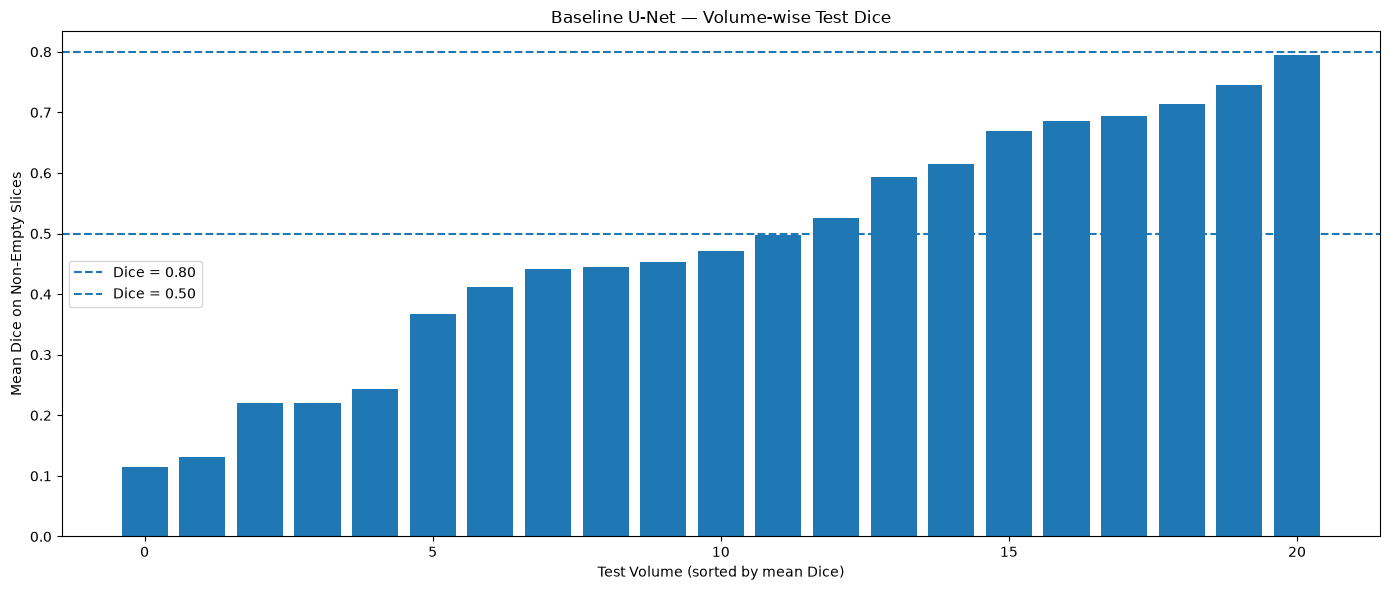

Saved plot:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_dice.png


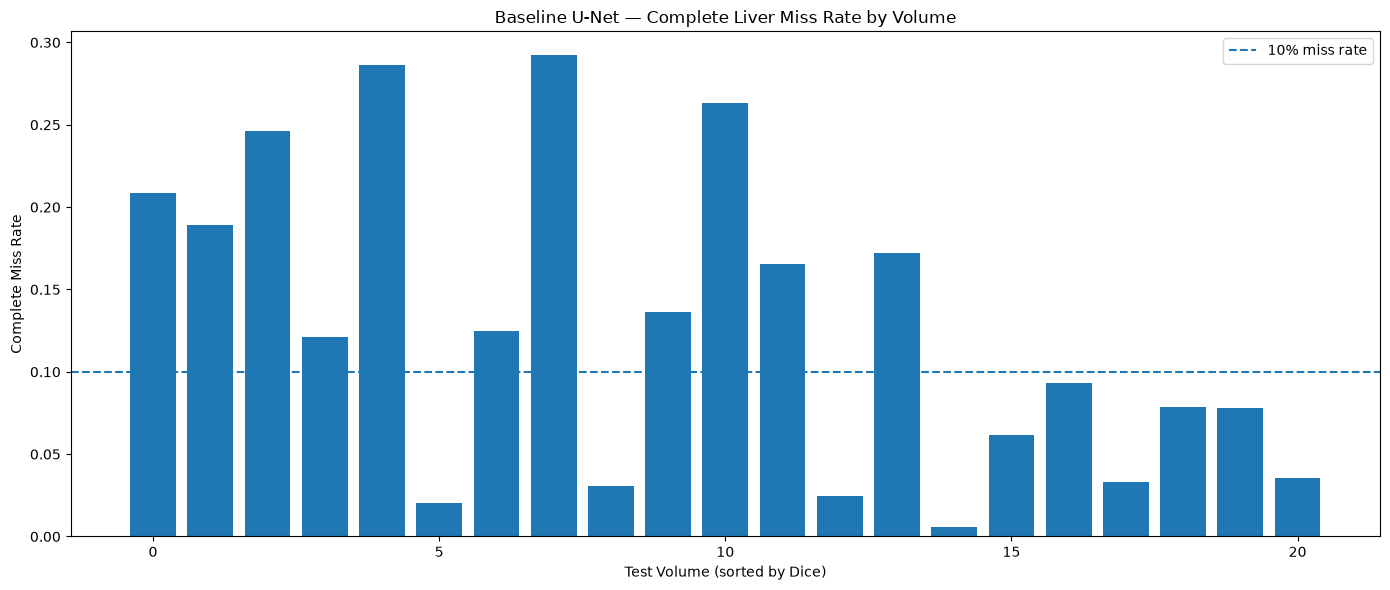

Saved plot:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_miss_rate.png

STEP 7A COMPLETE

The most important files are:
1. /mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_test_analysis.csv
2. /mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_dice.png
3. /mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_volume_wise_miss_rate.png

Next step: identify whether the worst volumes correspond to specific consecutive failure regions and inspect their slice-level predictions.


In [10]:
# ============================================================
# STEP 7A — VOLUME-WISE TEST ERROR ANALYSIS
# Liver CT Segmentation — Baseline U-Net
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/mnt/c/liverCTSegmentation")

ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"
TEST_CSV = ANALYSIS_DIR / "baseline_unet_test_per_slice_metrics.csv"

OUTPUT_CSV = ANALYSIS_DIR / "baseline_unet_volume_wise_test_analysis.csv"

print("=" * 70)
print("STEP 7A — VOLUME-WISE TEST ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 2. LOAD SAVED PER-SLICE TEST METRICS
# ------------------------------------------------------------

if not TEST_CSV.exists():
    raise FileNotFoundError(f"CSV not found:\n{TEST_CSV}")

df = pd.read_csv(TEST_CSV)

print(f"\nLoaded test metrics:")
print(f"Rows: {len(df):,}")
print(f"Columns: {list(df.columns)}")

display(df.head())

# ------------------------------------------------------------
# 3. IDENTIFY FILENAME COLUMN
# ------------------------------------------------------------

filename_candidates = [
    "image_path",
    "image",
    "filename",
    "file",
    "path",
    "image_file"
]

filename_col = None

for col in filename_candidates:
    if col in df.columns:
        filename_col = col
        break

if filename_col is None:
    raise ValueError(
        "Could not automatically find the filename column.\n"
        f"Available columns: {list(df.columns)}"
    )

print(f"\nFilename column: {filename_col}")

# ------------------------------------------------------------
# 4. EXTRACT VOLUME ID
#
# Expected filenames:
# Volume-001-000.png
# Volume-001-045.png
# Volume-131-500.png
# ------------------------------------------------------------

def extract_volume_id(path):
    name = Path(str(path)).name

    match = re.search(r"(Volume-\d+)", name, re.IGNORECASE)

    if match:
        return match.group(1)

    return "Unknown"


def extract_slice_id(path):
    name = Path(str(path)).name

    match = re.search(r"Volume-\d+-(\d+)", name, re.IGNORECASE)

    if match:
        return int(match.group(1))

    return -1


df["volume_id"] = df[filename_col].apply(extract_volume_id)
df["slice_id"] = df[filename_col].apply(extract_slice_id)

print("\nVolume extraction:")
print(f"Unique volumes: {df['volume_id'].nunique()}")

unknown_count = (df["volume_id"] == "Unknown").sum()

if unknown_count > 0:
    print(f"WARNING: {unknown_count} rows have unknown volume IDs.")
else:
    print("All rows successfully mapped to a volume.")

# ------------------------------------------------------------
# 5. IDENTIFY METRIC COLUMNS
# ------------------------------------------------------------

required_metrics = [
    "dice",
    "iou",
    "precision",
    "recall",
    "accuracy"
]

missing = [c for c in required_metrics if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing required metric columns: {missing}\n"
        f"Available columns: {list(df.columns)}"
    )

# ------------------------------------------------------------
# 6. IDENTIFY GT / PRED AREA COLUMNS
# ------------------------------------------------------------

gt_area_candidates = [
    "gt_area",
    "ground_truth_area",
    "true_area",
    "mask_area"
]

pred_area_candidates = [
    "pred_area",
    "prediction_area",
    "predicted_area"
]

gt_area_col = next(
    (c for c in gt_area_candidates if c in df.columns),
    None
)

pred_area_col = next(
    (c for c in pred_area_candidates if c in df.columns),
    None
)

print(f"\nGT area column   : {gt_area_col}")
print(f"Pred area column: {pred_area_col}")

# ------------------------------------------------------------
# 7. DEFINE NON-EMPTY SLICES
# ------------------------------------------------------------

if gt_area_col is not None:
    df["is_nonempty"] = df[gt_area_col] > 0
else:
    # Fallback based on recall/other information is not ideal,
    # so stop rather than silently making an incorrect assumption.
    raise ValueError(
        "GT area column is required to determine empty/non-empty slices."
    )

df["is_empty"] = ~df["is_nonempty"]

# ------------------------------------------------------------
# 8. COMPLETE MISS
#
# Non-empty ground truth but predicted liver area = 0
# ------------------------------------------------------------

if pred_area_col is not None:
    df["complete_miss"] = (
        (df["gt_area"] > 0) &
        (df[pred_area_col] == 0)
    )
else:
    print("WARNING: prediction area column unavailable.")
    df["complete_miss"] = False

# ------------------------------------------------------------
# 9. EMPTY-SLICE FALSE POSITIVE
#
# GT empty but prediction is non-empty
# ------------------------------------------------------------

if pred_area_col is not None:
    df["empty_false_positive"] = (
        (df["gt_area"] == 0) &
        (df[pred_area_col] > 0)
    )
else:
    df["empty_false_positive"] = False

# ------------------------------------------------------------
# 10. VOLUME-WISE AGGREGATION
# ------------------------------------------------------------

volume_rows = []

for volume_id, group in df.groupby("volume_id"):

    total_slices = len(group)

    nonempty = group[group["is_nonempty"]]

    empty = group[group["is_empty"]]

    n_nonempty = len(nonempty)
    n_empty = len(empty)

    # --------------------------------------------------------
    # Non-empty metrics
    # --------------------------------------------------------

    if n_nonempty > 0:

        dice_mean = nonempty["dice"].mean()
        dice_median = nonempty["dice"].median()

        iou_mean = nonempty["iou"].mean()
        precision_mean = nonempty["precision"].mean()
        recall_mean = nonempty["recall"].mean()

        accuracy_mean = nonempty["accuracy"].mean()

        complete_misses = nonempty["complete_miss"].sum()

        miss_rate = (
            complete_misses / n_nonempty
            if n_nonempty > 0 else 0
        )

        low_dice_count = (nonempty["dice"] < 0.20).sum()

        very_good_count = (nonempty["dice"] >= 0.80).sum()

        low_dice_rate = low_dice_count / n_nonempty

        very_good_rate = very_good_count / n_nonempty

        median_gt_area = nonempty["gt_area"].median()
        mean_gt_area = nonempty["gt_area"].mean()

    else:

        dice_mean = np.nan
        dice_median = np.nan
        iou_mean = np.nan
        precision_mean = np.nan
        recall_mean = np.nan
        accuracy_mean = np.nan

        complete_misses = 0
        miss_rate = np.nan

        low_dice_count = 0
        very_good_count = 0

        low_dice_rate = np.nan
        very_good_rate = np.nan

        median_gt_area = 0
        mean_gt_area = 0

    # --------------------------------------------------------
    # Empty-slice false positives
    # --------------------------------------------------------

    empty_fp_count = empty["empty_false_positive"].sum()

    empty_fp_rate = (
        empty_fp_count / n_empty
        if n_empty > 0 else 0
    )

    volume_rows.append({
        "volume_id": volume_id,

        "total_slices": total_slices,

        "nonempty_slices": n_nonempty,
        "empty_slices": n_empty,

        "nonempty_percentage":
            100 * n_nonempty / total_slices,

        "mean_dice": dice_mean,
        "median_dice": dice_median,

        "mean_iou": iou_mean,
        "mean_precision": precision_mean,
        "mean_recall": recall_mean,
        "mean_accuracy": accuracy_mean,

        "complete_misses": int(complete_misses),
        "miss_rate": miss_rate,

        "low_dice_count": int(low_dice_count),
        "low_dice_rate": low_dice_rate,

        "very_good_count": int(very_good_count),
        "very_good_rate": very_good_rate,

        "empty_false_positives": int(empty_fp_count),
        "empty_fp_rate": empty_fp_rate,

        "mean_gt_area": mean_gt_area,
        "median_gt_area": median_gt_area
    })

volume_df = pd.DataFrame(volume_rows)

# ------------------------------------------------------------
# 11. SORT BY PERFORMANCE
# ------------------------------------------------------------

volume_df = volume_df.sort_values(
    by="mean_dice",
    ascending=True
).reset_index(drop=True)

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

volume_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("VOLUME-WISE SUMMARY")
print("=" * 70)

print(f"\nTotal volumes analyzed: {len(volume_df)}")
print(f"Saved to:\n{OUTPUT_CSV}")

# ------------------------------------------------------------
# 13. WORST 15 VOLUMES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WORST 15 VOLUMES — NON-EMPTY DICE")
print("=" * 70)

worst_cols = [
    "volume_id",
    "total_slices",
    "nonempty_slices",
    "mean_dice",
    "median_dice",
    "mean_iou",
    "mean_precision",
    "mean_recall",
    "complete_misses",
    "miss_rate",
    "low_dice_rate",
    "empty_fp_rate"
]

display(
    volume_df[worst_cols]
    .head(15)
    .style
    .format({
        "mean_dice": "{:.4f}",
        "median_dice": "{:.4f}",
        "mean_iou": "{:.4f}",
        "mean_precision": "{:.4f}",
        "mean_recall": "{:.4f}",
        "miss_rate": "{:.2%}",
        "low_dice_rate": "{:.2%}",
        "empty_fp_rate": "{:.2%}"
    })
)

# ------------------------------------------------------------
# 14. BEST 15 VOLUMES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST 15 VOLUMES — NON-EMPTY DICE")
print("=" * 70)

display(
    volume_df[worst_cols]
    .sort_values("mean_dice", ascending=False)
    .head(15)
    .style
    .format({
        "mean_dice": "{:.4f}",
        "median_dice": "{:.4f}",
        "mean_iou": "{:.4f}",
        "mean_precision": "{:.4f}",
        "mean_recall": "{:.4f}",
        "miss_rate": "{:.2%}",
        "low_dice_rate": "{:.2%}",
        "empty_fp_rate": "{:.2%}"
    })
)

# ------------------------------------------------------------
# 15. VOLUMES WITH HIGHEST COMPLETE-MISS RATE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGHEST COMPLETE-MISS RATE")
print("=" * 70)

miss_cols = [
    "volume_id",
    "nonempty_slices",
    "complete_misses",
    "miss_rate",
    "mean_dice",
    "mean_iou",
    "mean_recall"
]

display(
    volume_df[
        volume_df["nonempty_slices"] > 0
    ]
    .sort_values("miss_rate", ascending=False)
    .head(15)[miss_cols]
    .round(4)
)
# ------------------------------------------------------------
# 16. VOLUMES WITH HIGHEST EMPTY-SLICE FALSE POSITIVES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGHEST EMPTY-SLICE FALSE-POSITIVE RATE")
print("=" * 70)

fp_cols = [
    "volume_id",
    "empty_slices",
    "empty_false_positives",
    "empty_fp_rate",
    "mean_dice"
]

display(
    volume_df[
        volume_df["empty_slices"] > 0
    ]
    .sort_values("empty_fp_rate", ascending=False)
    .head(15)[fp_cols]
    .style
    .format({
        "empty_fp_rate": "{:.2%}",
        "mean_dice": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 17. SUMMARY STATISTICS ACROSS VOLUMES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY ACROSS TEST VOLUMES")
print("=" * 70)

valid = volume_df[
    volume_df["nonempty_slices"] > 0
]

print(f"\nVolumes with non-empty slices: {len(valid)}")

print(
    f"Mean volume Dice:   "
    f"{valid['mean_dice'].mean():.4f}"
)

print(
    f"Median volume Dice: "
    f"{valid['mean_dice'].median():.4f}"
)

print(
    f"Best volume Dice:   "
    f"{valid['mean_dice'].max():.4f}"
)

print(
    f"Worst volume Dice:  "
    f"{valid['mean_dice'].min():.4f}"
)

print(
    f"Mean miss rate:     "
    f"{valid['miss_rate'].mean():.2%}"
)

print(
    f"Median miss rate:   "
    f"{valid['miss_rate'].median():.2%}"
)

print(
    f"Mean low-Dice rate: "
    f"{valid['low_dice_rate'].mean():.2%}"
)

# ------------------------------------------------------------
# 18. COUNT VOLUMES BY PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VOLUME PERFORMANCE DISTRIBUTION")
print("=" * 70)

volume_df["performance_category"] = pd.cut(
    volume_df["mean_dice"],
    bins=[-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf],
    labels=[
        "Very Poor (<0.20)",
        "Poor (0.20-0.40)",
        "Moderate (0.40-0.60)",
        "Good (0.60-0.80)",
        "Very Good (>=0.80)"
    ]
)

category_counts = (
    volume_df["performance_category"]
    .value_counts()
    .sort_index()
)

display(category_counts.to_frame("volume_count"))

# ------------------------------------------------------------
# 19. PLOT 1 — VOLUME-WISE DICE
# ------------------------------------------------------------

plot_df = volume_df[
    volume_df["nonempty_slices"] > 0
].copy()

plot_df = plot_df.sort_values(
    "mean_dice",
    ascending=True
)

plt.figure(figsize=(14, 6))

plt.bar(
    range(len(plot_df)),
    plot_df["mean_dice"]
)

plt.axhline(
    0.80,
    linestyle="--",
    label="Dice = 0.80"
)

plt.axhline(
    0.50,
    linestyle="--",
    label="Dice = 0.50"
)

plt.xlabel("Test Volume (sorted by mean Dice)")
plt.ylabel("Mean Dice on Non-Empty Slices")
plt.title("Baseline U-Net — Volume-wise Test Dice")

plt.legend()

plt.tight_layout()

dice_plot_path = ANALYSIS_DIR / "baseline_unet_volume_wise_dice.png"

plt.savefig(
    dice_plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Saved plot:\n{dice_plot_path}")

# ------------------------------------------------------------
# 20. PLOT 2 — MISS RATE BY VOLUME
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.bar(
    range(len(plot_df)),
    plot_df["miss_rate"]
)

plt.axhline(
    0.10,
    linestyle="--",
    label="10% miss rate"
)

plt.xlabel("Test Volume (sorted by Dice)")
plt.ylabel("Complete Miss Rate")
plt.title("Baseline U-Net — Complete Liver Miss Rate by Volume")

plt.legend()

plt.tight_layout()

miss_plot_path = ANALYSIS_DIR / "baseline_unet_volume_wise_miss_rate.png"

plt.savefig(
    miss_plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Saved plot:\n{miss_plot_path}")

# ------------------------------------------------------------
# 21. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 7A COMPLETE")
print("=" * 70)

print(
    "\nThe most important files are:"
)

print(f"1. {OUTPUT_CSV}")
print(f"2. {dice_plot_path}")
print(f"3. {miss_plot_path}")

print(
    "\nNext step: identify whether the worst volumes correspond "
    "to specific consecutive failure regions and inspect their "
    "slice-level predictions."
)

In [9]:
!pip install jinja2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 1.9 MB/s eta 0:00:0000:010:01


In [11]:
# ============================================================
# STEP 7B — FAILURE SEQUENCE + WORST VOLUME ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re

BASE_DIR = Path("/mnt/c/liverCTSegmentation")
ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"

TEST_CSV = ANALYSIS_DIR / "baseline_unet_test_per_slice_metrics.csv"

print("=" * 70)
print("STEP 7B — FAILURE SEQUENCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD TEST METRICS
# ------------------------------------------------------------

df = pd.read_csv(TEST_CSV)

print(f"\nTotal test slices: {len(df):,}")

# ------------------------------------------------------------
# 2. EXTRACT VOLUME AND SLICE IDS
# ------------------------------------------------------------

def extract_volume_id(path):
    name = Path(str(path)).name
    match = re.search(r"(Volume-\d+)", name, re.IGNORECASE)
    return match.group(1) if match else "Unknown"


def extract_slice_id(path):
    name = Path(str(path)).name
    match = re.search(r"Volume-\d+-(\d+)", name, re.IGNORECASE)
    return int(match.group(1)) if match else -1


df["volume_id"] = df["image_path"].apply(extract_volume_id)
df["slice_id"] = df["image_path"].apply(extract_slice_id)

# ------------------------------------------------------------
# 3. IDENTIFY FAILURE TYPES
# ------------------------------------------------------------

df["complete_miss"] = (
    (df["gt_area"] > 0) &
    (df["pred_area"] == 0)
)

df["very_poor"] = (
    (df["gt_area"] > 0) &
    (df["dice"] < 0.20)
)

df["poor"] = (
    (df["gt_area"] > 0) &
    (df["dice"] < 0.40)
)

df["good"] = (
    (df["gt_area"] > 0) &
    (df["dice"] >= 0.80)
)

df["empty_false_positive"] = (
    (df["gt_area"] == 0) &
    (df["pred_area"] > 0)
)

# ------------------------------------------------------------
# 4. COMPLETE-MISS SLICES
# ------------------------------------------------------------

misses = df[df["complete_miss"]].copy()

print("\n" + "=" * 70)
print("COMPLETE-MISS ANALYSIS")
print("=" * 70)

print(f"\nTotal complete misses: {len(misses)}")

print("\nComplete misses by volume:")

miss_by_volume = (
    misses
    .groupby("volume_id")
    .size()
    .sort_values(ascending=False)
)

print(miss_by_volume)

# ------------------------------------------------------------
# 5. SHOW COMPLETE MISSES BY VOLUME + SLICE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPLETE-MISS SLICE RANGES BY VOLUME")
print("=" * 70)

for volume_id, group in misses.groupby("volume_id"):

    slices = sorted(group["slice_id"].tolist())

    if len(slices) == 0:
        continue

    # Create consecutive ranges
    ranges = []

    start = slices[0]
    prev = slices[0]

    for s in slices[1:]:

        if s == prev + 1:
            prev = s

        else:
            ranges.append((start, prev))
            start = s
            prev = s

    ranges.append((start, prev))

    range_text = []

    for a, b in ranges:

        if a == b:
            range_text.append(str(a))
        else:
            range_text.append(f"{a}-{b}")

    print(
        f"\n{volume_id}: "
        f"{len(slices)} complete misses"
    )

    print(
        "Consecutive ranges:",
        ", ".join(range_text)
    )

# ------------------------------------------------------------
# 6. WORST SLICE SEQUENCES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VERY POOR DICE (<0.20) SEQUENCES")
print("=" * 70)

very_poor = df[df["very_poor"]].copy()

for volume_id, group in very_poor.groupby("volume_id"):

    slices = sorted(group["slice_id"].tolist())

    if len(slices) == 0:
        continue

    ranges = []

    start = slices[0]
    prev = slices[0]

    for s in slices[1:]:

        if s == prev + 1:
            prev = s

        else:
            ranges.append((start, prev))
            start = s
            prev = s

    ranges.append((start, prev))

    range_text = []

    for a, b in ranges:

        if a == b:
            range_text.append(str(a))
        else:
            range_text.append(f"{a}-{b}")

    print(
        f"\n{volume_id}: "
        f"{len(slices)} very-poor slices"
    )

    print(
        "Ranges:",
        ", ".join(range_text)
    )

# ------------------------------------------------------------
# 7. WORST 30 NON-EMPTY SLICES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WORST 30 NON-EMPTY TEST SLICES")
print("=" * 70)

worst_slices = (
    df[df["gt_area"] > 0]
    .sort_values("dice", ascending=True)
    .head(30)
)

display(
    worst_slices[
        [
            "index",
            "volume_id",
            "slice_id",
            "dice",
            "iou",
            "precision",
            "recall",
            "gt_area",
            "pred_area",
            "prediction_type"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 8. LARGEST LIVER COMPLETELY MISSED
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LARGEST LIVER AREAS COMPLETELY MISSED")
print("=" * 70)

largest_missed = (
    misses
    .sort_values("gt_area", ascending=False)
    .head(30)
)

display(
    largest_missed[
        [
            "index",
            "volume_id",
            "slice_id",
            "dice",
            "gt_area",
            "pred_area",
            "precision",
            "recall"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 9. VOLUME-WISE SEQUENCE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VOLUME-WISE FAILURE SUMMARY")
print("=" * 70)

summary = []

for volume_id, group in df.groupby("volume_id"):

    nonempty = group[group["gt_area"] > 0]

    if len(nonempty) == 0:
        continue

    summary.append({
        "volume_id": volume_id,

        "nonempty_slices": len(nonempty),

        "mean_dice": nonempty["dice"].mean(),

        "median_dice": nonempty["dice"].median(),

        "complete_misses":
            nonempty["complete_miss"].sum(),

        "miss_rate":
            nonempty["complete_miss"].mean(),

        "very_poor_count":
            nonempty["very_poor"].sum(),

        "very_poor_rate":
            nonempty["very_poor"].mean(),

        "good_count":
            nonempty["good"].sum(),

        "good_rate":
            nonempty["good"].mean(),

        "mean_gt_area":
            nonempty["gt_area"].mean(),

        "median_gt_area":
            nonempty["gt_area"].median(),

        "max_gt_area":
            nonempty["gt_area"].max()
    })

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    "mean_dice"
)

display(
    summary_df.round(4)
)

# ------------------------------------------------------------
# 10. SAVE
# ------------------------------------------------------------

OUTPUT_PATH = (
    ANALYSIS_DIR /
    "baseline_unet_failure_sequence_analysis.csv"
)

summary_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    f"\nSaved:\n{OUTPUT_PATH}"
)

# ------------------------------------------------------------
# 11. FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 7B COMPLETE")
print("=" * 70)

print(
    "\nThis analysis tells us exactly where the model "
    "fails inside each CT volume."
)

STEP 7B — FAILURE SEQUENCE ANALYSIS

Total test slices: 10,001

COMPLETE-MISS ANALYSIS

Total complete misses: 411

Complete misses by volume:
volume_id
Volume-094    71
Volume-004    61
Volume-130    50
Volume-086    46
Volume-062    26
Volume-069    25
Volume-114    20
Volume-013    17
Volume-070    15
Volume-124    14
Volume-003    13
Volume-064     8
Volume-017     7
Volume-075     7
Volume-027     7
Volume-029     7
Volume-006     6
Volume-054     5
Volume-118     3
Volume-028     2
Volume-011     1
dtype: int64

COMPLETE-MISS SLICE RANGES BY VOLUME

Volume-003: 13 complete misses
Consecutive ranges: 303-305, 444-453

Volume-004: 61 complete misses
Consecutive ranges: 348-391, 431, 451, 453-457, 459-464, 466-467, 595-596

Volume-006: 6 complete misses
Consecutive ranges: 305-306, 399, 488-490

Volume-011: 1 complete misses
Consecutive ranges: 272

Volume-013: 17 complete misses
Consecutive ranges: 273, 276-283, 287-289, 293-295, 330, 413

Volume-017: 7 complete misses
Consecutive 

,index,volume_id,slice_id,dice,iou,precision,recall,gt_area,pred_area,prediction_type
6646,6646,Volume-086,513,0.0,0.0,1.0,0.0,2355,0,Missed Liver
6642,6642,Volume-086,509,0.0,0.0,1.0,0.0,2338,0,Missed Liver
444,444,Volume-003,444,0.0,0.0,1.0,0.0,2332,0,Missed Liver
6641,6641,Volume-086,508,0.0,0.0,1.0,0.0,2321,0,Missed Liver
445,445,Volume-003,445,0.0,0.0,1.0,0.0,2275,0,Missed Liver
6664,6664,Volume-086,531,0.0,0.0,1.0,0.0,2258,0,Missed Liver
6665,6665,Volume-086,532,0.0,0.0,1.0,0.0,2245,0,Missed Liver
446,446,Volume-003,446,0.0,0.0,1.0,0.0,2235,0,Missed Liver
6666,6666,Volume-086,533,0.0,0.0,1.0,0.0,2230,0,Missed Liver
6667,6667,Volume-086,534,0.0,0.0,1.0,0.0,2225,0,Missed Liver



LARGEST LIVER AREAS COMPLETELY MISSED


,index,volume_id,slice_id,dice,gt_area,pred_area,precision,recall
6646,6646,Volume-086,513,0.0,2355,0,1.0,0.0
6642,6642,Volume-086,509,0.0,2338,0,1.0,0.0
444,444,Volume-003,444,0.0,2332,0,1.0,0.0
6641,6641,Volume-086,508,0.0,2321,0,1.0,0.0
445,445,Volume-003,445,0.0,2275,0,1.0,0.0
6664,6664,Volume-086,531,0.0,2258,0,1.0,0.0
6665,6665,Volume-086,532,0.0,2245,0,1.0,0.0
446,446,Volume-003,446,0.0,2235,0,1.0,0.0
6666,6666,Volume-086,533,0.0,2230,0,1.0,0.0
6667,6667,Volume-086,534,0.0,2225,0,1.0,0.0



VOLUME-WISE FAILURE SUMMARY


,volume_id,nonempty_slices,mean_dice,median_dice,complete_misses,miss_rate,very_poor_count,very_poor_rate,good_count,good_rate,mean_gt_area,median_gt_area,max_gt_area
20,Volume-130,240,0.1145,0.0326,50,0.2083,180,0.7500,0,0.0000,387.8542,348.5,834
14,Volume-075,37,0.1315,0.0000,7,0.1892,29,0.7838,2,0.0541,556.3243,403.0,2048
1,Volume-004,248,0.2205,0.0701,61,0.2460,148,0.5968,3,0.0121,382.7823,317.0,907
4,Volume-013,140,0.2211,0.0212,17,0.1214,99,0.7071,19,0.1357,249.5714,46.0,1918
16,Volume-094,248,0.2432,0.0650,71,0.2863,174,0.7016,44,0.1774,247.5605,67.5,1424
7,Volume-028,98,0.3677,0.1829,2,0.0204,52,0.5306,18,0.1837,278.8980,139.5,3042
19,Volume-124,112,0.4111,0.1924,14,0.1250,57,0.5089,37,0.3304,174.7768,127.0,715
10,Volume-062,89,0.4422,0.2398,26,0.2921,42,0.4719,36,0.4045,938.7303,818.0,2091
6,Volume-027,228,0.4448,0.3651,7,0.0307,112,0.4912,75,0.3289,200.6360,80.5,1464
13,Volume-070,110,0.4525,0.2932,15,0.1364,46,0.4182,35,0.3182,401.5000,232.5,1800



Saved:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_failure_sequence_analysis.csv

STEP 7B COMPLETE

This analysis tells us exactly where the model fails inside each CT volume.


STEP 7C — VISUAL FAILURE SEQUENCE ANALYSIS

Test CSV loaded: 10,001 rows

Selected slices:
 index  volume_id  slice_id   dice    iou  gt_area  pred_area  precision  recall prediction_type
   440 Volume-003       440 0.9837 0.9678     2470       2424     0.9930  0.9745       Non-empty
   441 Volume-003       441 0.7434 0.5916     2444       1457     0.9952  0.5933       Non-empty
   442 Volume-003       442 0.0116 0.0058     2396         14     1.0000  0.0058       Non-empty
   443 Volume-003       443 0.0126 0.0063     2368         16     0.9375  0.0063       Non-empty
   444 Volume-003       444 0.0000 0.0000     2332          0     1.0000  0.0000    Missed Liver
   445 Volume-003       445 0.0000 0.0000     2275          0     1.0000  0.0000    Missed Liver
   446 Volume-003       446 0.0000 0.0000     2235          0     1.0000  0.0000    Missed Liver
   447 Volume-003       447 0.0000 0.0000     2176          0     1.0000  0.0000    Missed Liver
   448 Volume-003       448 0.0000 0

I0000 00:00:1791377147.260115    1024 service.cc:148] XLA service 0x779b01c15770 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791377147.260490    1024 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-10-07 12:45:47.334813: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


Inference complete.

RECALCULATED METRICS


I0000 00:00:1791377150.487556    1024 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,slice_id,dice_recalculated,iou_recalculated,gt_area,pred_area,precision,recall
0,440,0.9837,0.9678,2470,2424,0.9930,0.9745
1,441,0.7398,0.5871,2444,1446,0.9952,0.5888
2,442,0.0124,0.0063,2396,15,1.0000,0.0063
3,443,0.0126,0.0063,2368,16,0.9375,0.0063
4,444,0.0000,0.0000,2332,0,1.0000,0.0000
5,445,0.0000,0.0000,2275,0,1.0000,0.0000
6,446,0.0000,0.0000,2235,0,1.0000,0.0000
7,447,0.0000,0.0000,2176,0,1.0000,0.0000
8,448,0.0000,0.0000,2123,0,1.0000,0.0000
9,449,0.0000,0.0000,2073,0,1.0000,0.0000


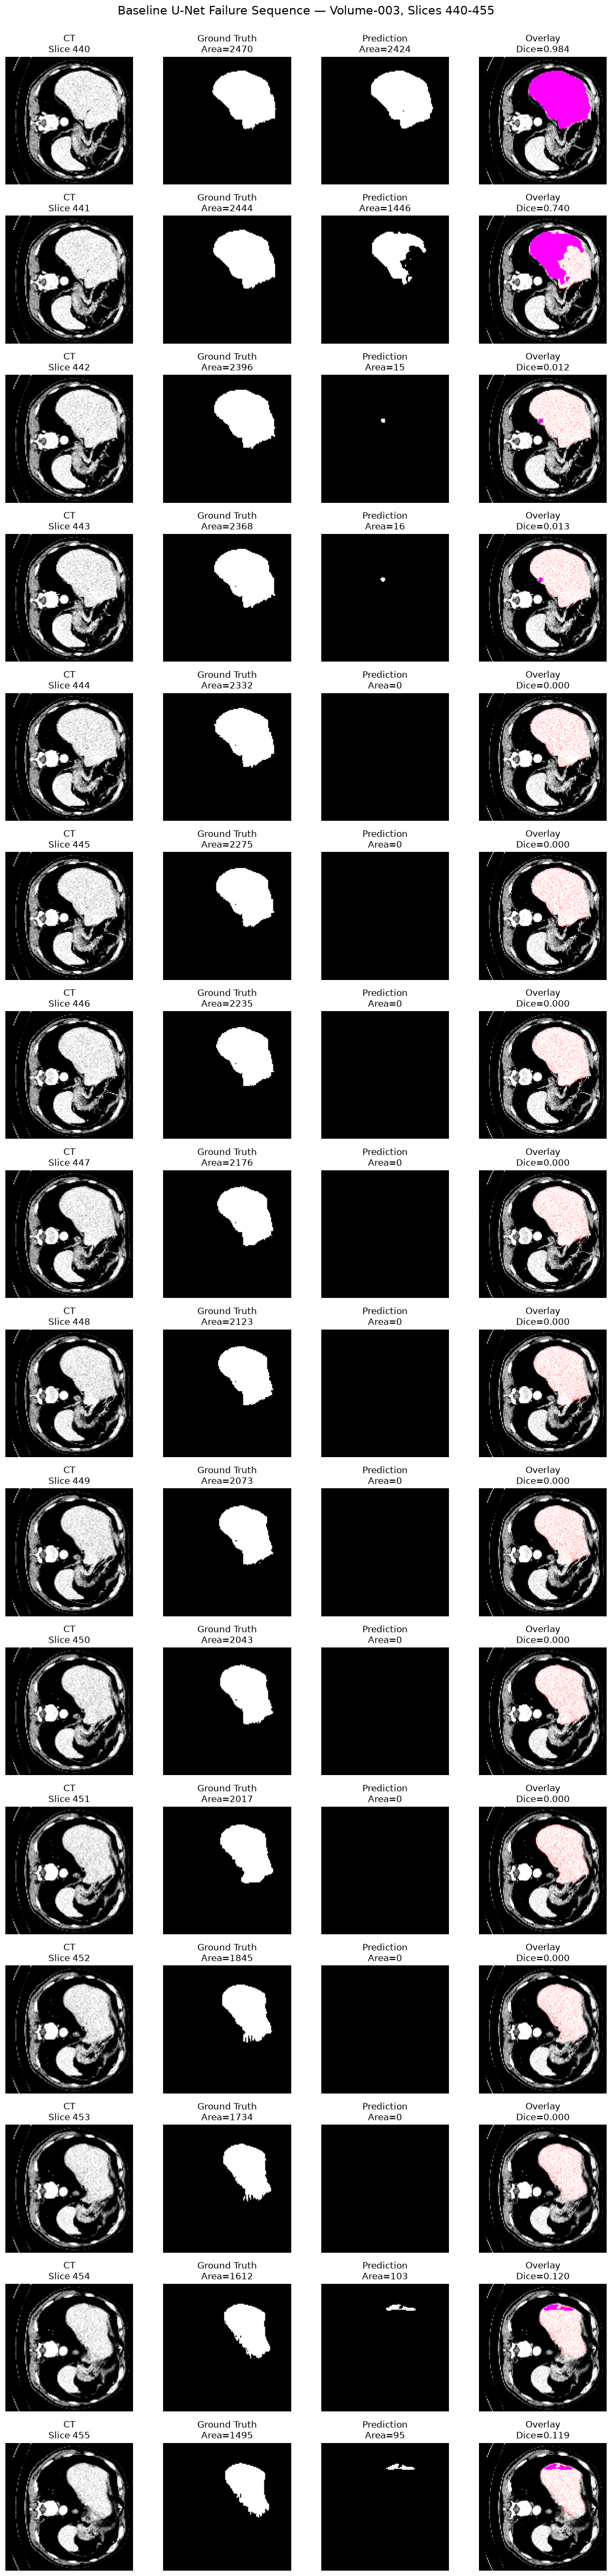


Saved visualization:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_Volume-003_slices_440_455.png
Saved metrics:
/mnt/c/liverCTSegmentation/outputs/analysis/baseline_unet_Volume-003_slices_440_455_metrics.csv

Memory cleanup completed.

STEP 7C COMPLETE


In [12]:
# ============================================================
# STEP 7C — VISUAL FAILURE SEQUENCE ANALYSIS
# Volume-003, slices 440–455
# ============================================================

import os
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = Path("/mnt/c/liverCTSegmentation")

ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"

CHECKPOINT = (
    BASE_DIR /
    "outputs" /
    "checkpoints" /
    "baseline_unet_best_recovered.keras"
)

TEST_CSV = (
    ANALYSIS_DIR /
    "baseline_unet_test_per_slice_metrics.csv"
)

VOLUME_ID = "Volume-003"

START_SLICE = 440
END_SLICE = 455

OUTPUT_FIGURE = (
    ANALYSIS_DIR /
    f"baseline_unet_{VOLUME_ID}_slices_{START_SLICE}_{END_SLICE}.png"
)

print("=" * 70)
print("STEP 7C — VISUAL FAILURE SEQUENCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 2. LOAD TEST CSV
# ------------------------------------------------------------

df = pd.read_csv(TEST_CSV)

print(f"\nTest CSV loaded: {len(df):,} rows")

# ------------------------------------------------------------
# 3. EXTRACT VOLUME / SLICE IDS
# ------------------------------------------------------------

def extract_slice_id(path):
    name = Path(str(path)).name

    # Example:
    # Volume-003-444.png
    import re

    match = re.search(
        r"Volume-\d+-(\d+)",
        name,
        re.IGNORECASE
    )

    return int(match.group(1)) if match else -1


def extract_volume_id(path):
    name = Path(str(path)).name

    import re

    match = re.search(
        r"(Volume-\d+)",
        name,
        re.IGNORECASE
    )

    return match.group(1) if match else "Unknown"


df["volume_id"] = df["image_path"].apply(extract_volume_id)
df["slice_id"] = df["image_path"].apply(extract_slice_id)

# ------------------------------------------------------------
# 4. SELECT THE FAILURE SEQUENCE
# ------------------------------------------------------------

selected = df[
    (df["volume_id"] == VOLUME_ID) &
    (df["slice_id"] >= START_SLICE) &
    (df["slice_id"] <= END_SLICE)
].copy()

selected = selected.sort_values("slice_id")

print("\nSelected slices:")
print(selected[
    [
        "index",
        "volume_id",
        "slice_id",
        "dice",
        "iou",
        "gt_area",
        "pred_area",
        "precision",
        "recall",
        "prediction_type"
    ]
].round(4).to_string(index=False))

print(f"\nNumber of selected slices: {len(selected)}")

if len(selected) == 0:
    raise ValueError(
        "No matching slices were found."
    )

# ------------------------------------------------------------
# 5. LOAD MODEL
# ------------------------------------------------------------

print("\nLoading baseline U-Net...")

model = tf.keras.models.load_model(
    CHECKPOINT,
    compile=False
)

print("Model loaded successfully.")
print(f"Parameters: {model.count_params():,}")

# ------------------------------------------------------------
# 6. IMAGE / MASK LOADER
# ------------------------------------------------------------

def load_image(path):
    image = tf.io.read_file(str(path))
    image = tf.image.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [128, 128],
        method=tf.image.ResizeMethod.BILINEAR
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image.numpy()


def load_mask(path):
    mask = tf.io.read_file(str(path))
    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.image.resize(
        mask,
        [128, 128],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    mask = tf.cast(
        mask > 127,
        tf.float32
    )

    return mask.numpy()


# ------------------------------------------------------------
# 7. LOAD SELECTED IMAGES AND MASKS
# ------------------------------------------------------------

images = []
masks = []

valid_rows = []

for _, row in selected.iterrows():

    try:

        image = load_image(row["image_path"])
        mask = load_mask(row["mask_path"])

        images.append(image)
        masks.append(mask)

        valid_rows.append(row)

    except Exception as e:

        print(
            f"ERROR loading slice "
            f"{row['slice_id']}: {e}"
        )

selected = pd.DataFrame(valid_rows).reset_index(drop=True)

images = np.asarray(images, dtype=np.float32)
masks = np.asarray(masks, dtype=np.float32)

print(
    f"\nLoaded image array: {images.shape}"
)

print(
    f"Loaded mask array : {masks.shape}"
)

# ------------------------------------------------------------
# 8. RUN PREDICTION
# ------------------------------------------------------------

print("\nRunning inference...")

predictions = model.predict(
    images,
    batch_size=4,
    verbose=0
)

predictions = np.asarray(
    predictions,
    dtype=np.float32
)

# Binary masks
pred_masks = (
    predictions >= 0.5
).astype(np.float32)

print("Inference complete.")

# ------------------------------------------------------------
# 9. CALCULATE METRICS AGAIN
# ------------------------------------------------------------

results = []

for i, row in selected.iterrows():

    gt = masks[i, :, :, 0]
    pred = pred_masks[i, :, :, 0]

    gt_binary = gt > 0.5
    pred_binary = pred > 0.5

    intersection = np.logical_and(
        gt_binary,
        pred_binary
    ).sum()

    gt_area = gt_binary.sum()
    pred_area = pred_binary.sum()

    union = np.logical_or(
        gt_binary,
        pred_binary
    ).sum()

    dice = (
        2.0 * intersection /
        (gt_area + pred_area)
        if (gt_area + pred_area) > 0
        else 1.0
    )

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    tp = intersection

    fp = np.logical_and(
        ~gt_binary,
        pred_binary
    ).sum()

    fn = np.logical_and(
        gt_binary,
        ~pred_binary
    ).sum()

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 1.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 1.0
    )

    results.append({
        "slice_id": int(row["slice_id"]),
        "dice_recalculated": dice,
        "iou_recalculated": iou,
        "gt_area": int(gt_area),
        "pred_area": int(pred_area),
        "precision": precision,
        "recall": recall
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("RECALCULATED METRICS")
print("=" * 70)

display(
    results_df.round(4)
)

# ------------------------------------------------------------
# 10. CREATE VISUALIZATION
#
# 4 columns:
# CT | Ground Truth | Prediction | Overlay
#
# 16 slices = 4 rows x 16? 
# We use 4 slices per figure row.
# ------------------------------------------------------------

n = len(selected)

fig, axes = plt.subplots(
    nrows=n,
    ncols=4,
    figsize=(12, 3.0 * n)
)

if n == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for i in range(n):

    image = images[i, :, :, 0]
    gt = masks[i, :, :, 0]
    pred = pred_masks[i, :, :, 0]

    dice = results_df.loc[
        i,
        "dice_recalculated"
    ]

    slice_id = int(
        selected.loc[i, "slice_id"]
    )

    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    axes[i, 0].imshow(
        image,
        cmap="gray"
    )

    axes[i, 0].set_title(
        f"CT\nSlice {slice_id}"
    )

    axes[i, 0].axis("off")

    # --------------------------------------------------------
    # GROUND TRUTH
    # --------------------------------------------------------

    axes[i, 1].imshow(
        gt,
        cmap="gray"
    )

    axes[i, 1].set_title(
        f"Ground Truth\nArea={int(gt.sum())}"
    )

    axes[i, 1].axis("off")

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    axes[i, 2].imshow(
        pred,
        cmap="gray"
    )

    axes[i, 2].set_title(
        f"Prediction\nArea={int(pred.sum())}"
    )

    axes[i, 2].axis("off")

    # --------------------------------------------------------
    # OVERLAY
    #
    # CT = grayscale background
    # GT = red
    # Prediction = blue
    # Overlap = purple
    # --------------------------------------------------------

    overlay = np.stack(
        [image, image, image],
        axis=-1
    )

    gt_mask = gt > 0.5
    pred_mask = pred > 0.5

    # Ground truth contribution
    overlay[gt_mask, 0] = 1.0

    # Prediction contribution
    overlay[pred_mask, 2] = 1.0

    # Both GT + prediction
    both = gt_mask & pred_mask

    overlay[both, 0] = 1.0
    overlay[both, 1] = 0.0
    overlay[both, 2] = 1.0

    axes[i, 3].imshow(
        overlay
    )

    axes[i, 3].set_title(
        f"Overlay\nDice={dice:.3f}"
    )

    axes[i, 3].axis("off")


fig.suptitle(
    f"Baseline U-Net Failure Sequence — "
    f"{VOLUME_ID}, Slices {START_SLICE}-{END_SLICE}",
    fontsize=16,
    y=1.0
)

plt.tight_layout()

# ------------------------------------------------------------
# 11. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_FIGURE,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nSaved visualization:\n{OUTPUT_FIGURE}"
)

# ------------------------------------------------------------
# 12. SAVE SELECTED METRICS
# ------------------------------------------------------------

OUTPUT_CSV = (
    ANALYSIS_DIR /
    f"baseline_unet_{VOLUME_ID}_"
    f"slices_{START_SLICE}_{END_SLICE}_metrics.csv"
)

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print(
    f"Saved metrics:\n{OUTPUT_CSV}"
)

# ------------------------------------------------------------
# 13. MEMORY CLEANUP
# ------------------------------------------------------------

del images
del masks
del predictions
del pred_masks
del model

gc.collect()

print("\nMemory cleanup completed.")

print("\n" + "=" * 70)
print("STEP 7C COMPLETE")
print("=" * 70)

STEP 7D — INPUT INTENSITY + RAW PROBABILITY ANALYSIS

Selected 16 slices from Volume-003
Image tensor: (16, 128, 128, 1)

Loading model...
Model loaded.

Running inference...
Inference complete.

INPUT + RAW MODEL OUTPUT


,slice,gt_area,image_mean,image_std,image_min,image_max,prob_mean,prob_std,prob_min,prob_max,pct_prob_ge_0.10,pct_prob_ge_0.25,pct_prob_ge_0.50,pct_prob_ge_0.75,pct_prob_ge_0.90
0,440,2470,0.3050,0.4027,0.0,1.0,0.1475,0.3529,0.0,0.9999,14.9719,14.8621,14.7949,14.7339,14.5752
1,441,2444,0.3024,0.4020,0.0,1.0,0.0886,0.2749,0.0,0.9999,9.8999,9.3140,8.8257,8.4412,7.9895
2,442,2396,0.3004,0.4011,0.0,1.0,0.0012,0.0277,0.0,0.9947,0.1465,0.1221,0.0916,0.0793,0.0549
3,443,2368,0.2971,0.3995,0.0,1.0,0.0012,0.0273,0.0,0.9946,0.1648,0.1221,0.0977,0.0671,0.0549
4,444,2332,0.2941,0.3978,0.0,1.0,0.0001,0.0002,0.0,0.0089,0.0000,0.0000,0.0000,0.0000,0.0000
5,445,2275,0.2897,0.3958,0.0,1.0,0.0001,0.0008,0.0,0.0880,0.0000,0.0000,0.0000,0.0000,0.0000
6,446,2235,0.2847,0.3930,0.0,1.0,0.0000,0.0002,0.0,0.0131,0.0000,0.0000,0.0000,0.0000,0.0000
7,447,2176,0.2791,0.3898,0.0,1.0,0.0001,0.0003,0.0,0.0069,0.0000,0.0000,0.0000,0.0000,0.0000
8,448,2123,0.2738,0.3864,0.0,1.0,0.0001,0.0003,0.0,0.0091,0.0000,0.0000,0.0000,0.0000,0.0000
9,449,2073,0.2692,0.3841,0.0,1.0,0.0001,0.0004,0.0,0.0151,0.0000,0.0000,0.0000,0.0000,0.0000



CRITICAL TRANSITION: SLICES 440–445


,slice,gt_area,image_mean,image_std,image_min,image_max,prob_mean,prob_std,prob_min,prob_max,pct_prob_ge_0.10,pct_prob_ge_0.25,pct_prob_ge_0.50,pct_prob_ge_0.75,pct_prob_ge_0.90
0,440,2470,0.3050,0.4027,0.0,1.0,0.1475,0.3529,0.0,0.9999,14.9719,14.8621,14.7949,14.7339,14.5752
1,441,2444,0.3024,0.4020,0.0,1.0,0.0886,0.2749,0.0,0.9999,9.8999,9.3140,8.8257,8.4412,7.9895
2,442,2396,0.3004,0.4011,0.0,1.0,0.0012,0.0277,0.0,0.9947,0.1465,0.1221,0.0916,0.0793,0.0549
3,443,2368,0.2971,0.3995,0.0,1.0,0.0012,0.0273,0.0,0.9946,0.1648,0.1221,0.0977,0.0671,0.0549
4,444,2332,0.2941,0.3978,0.0,1.0,0.0001,0.0002,0.0,0.0089,0.0000,0.0000,0.0000,0.0000,0.0000
5,445,2275,0.2897,0.3958,0.0,1.0,0.0001,0.0008,0.0,0.0880,0.0000,0.0000,0.0000,0.0000,0.0000



Saved:
/mnt/c/liverCTSegmentation/outputs/analysis/Volume-003_440-455_probability_intensity_analysis.csv


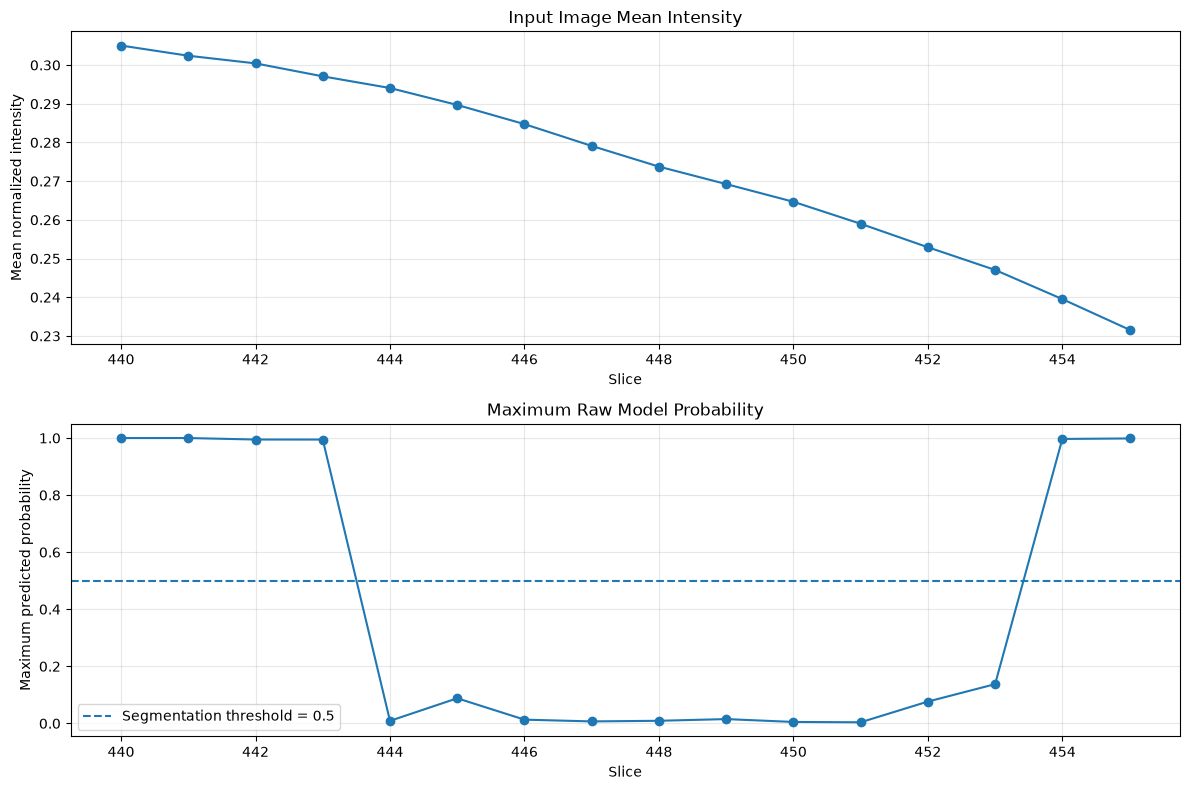


Saved plot:
/mnt/c/liverCTSegmentation/outputs/analysis/Volume-003_440-455_intensity_probability.png

Memory cleanup completed.

STEP 7D COMPLETE


In [13]:
# ============================================================
# STEP 7D — INPUT INTENSITY + RAW PROBABILITY ANALYSIS
# Volume-003, slices 440–455
# ============================================================

import gc
import re
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

BASE_DIR = Path("/mnt/c/liverCTSegmentation")

ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"

CHECKPOINT = (
    BASE_DIR /
    "outputs" /
    "checkpoints" /
    "baseline_unet_best_recovered.keras"
)

TEST_CSV = (
    ANALYSIS_DIR /
    "baseline_unet_test_per_slice_metrics.csv"
)

VOLUME_ID = "Volume-003"

START_SLICE = 440
END_SLICE = 455

print("=" * 70)
print("STEP 7D — INPUT INTENSITY + RAW PROBABILITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD CSV
# ------------------------------------------------------------

df = pd.read_csv(TEST_CSV)

def extract_volume_id(path):
    name = Path(str(path)).name

    match = re.search(
        r"(Volume-\d+)",
        name,
        re.IGNORECASE
    )

    return match.group(1) if match else "Unknown"


def extract_slice_id(path):
    name = Path(str(path)).name

    match = re.search(
        r"Volume-\d+-(\d+)",
        name,
        re.IGNORECASE
    )

    return int(match.group(1)) if match else -1


df["volume_id"] = df["image_path"].apply(
    extract_volume_id
)

df["slice_id"] = df["image_path"].apply(
    extract_slice_id
)

selected = df[
    (df["volume_id"] == VOLUME_ID) &
    (df["slice_id"] >= START_SLICE) &
    (df["slice_id"] <= END_SLICE)
].sort_values("slice_id").reset_index(drop=True)

print(
    f"\nSelected {len(selected)} slices "
    f"from {VOLUME_ID}"
)

# ------------------------------------------------------------
# 2. LOAD IMAGES
# ------------------------------------------------------------

images = []

for _, row in selected.iterrows():

    image = tf.io.read_file(
        str(row["image_path"])
    )

    image = tf.image.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [128, 128],
        method=tf.image.ResizeMethod.BILINEAR
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    images.append(
        image.numpy()
    )

images = np.asarray(
    images,
    dtype=np.float32
)

print(
    f"Image tensor: {images.shape}"
)

# ------------------------------------------------------------
# 3. LOAD MODEL
# ------------------------------------------------------------

print("\nLoading model...")

model = tf.keras.models.load_model(
    CHECKPOINT,
    compile=False
)

print("Model loaded.")

# ------------------------------------------------------------
# 4. RAW PROBABILITY PREDICTIONS
# ------------------------------------------------------------

print("\nRunning inference...")

probabilities = model.predict(
    images,
    batch_size=4,
    verbose=0
)

probabilities = np.asarray(
    probabilities,
    dtype=np.float32
)

print("Inference complete.")

# ------------------------------------------------------------
# 5. ANALYZE EACH SLICE
# ------------------------------------------------------------

rows = []

for i, row in selected.iterrows():

    image = images[i, :, :, 0]

    prob = probabilities[i, :, :, 0]

    gt_area = int(row["gt_area"])

    # Input statistics
    image_mean = float(image.mean())
    image_std = float(image.std())
    image_min = float(image.min())
    image_max = float(image.max())

    # Probability statistics
    prob_mean = float(prob.mean())
    prob_std = float(prob.std())
    prob_min = float(prob.min())
    prob_max = float(prob.max())

    # Percentage of pixels above thresholds
    pct_01 = float(
        (prob >= 0.10).mean() * 100
    )

    pct_025 = float(
        (prob >= 0.25).mean() * 100
    )

    pct_05 = float(
        (prob >= 0.50).mean() * 100
    )

    pct_075 = float(
        (prob >= 0.75).mean() * 100
    )

    pct_09 = float(
        (prob >= 0.90).mean() * 100
    )

    rows.append({

        "slice": int(row["slice_id"]),

        "gt_area": gt_area,

        # Image statistics
        "image_mean": image_mean,
        "image_std": image_std,
        "image_min": image_min,
        "image_max": image_max,

        # Raw probability statistics
        "prob_mean": prob_mean,
        "prob_std": prob_std,
        "prob_min": prob_min,
        "prob_max": prob_max,

        # Threshold response
        "pct_prob_ge_0.10": pct_01,
        "pct_prob_ge_0.25": pct_025,
        "pct_prob_ge_0.50": pct_05,
        "pct_prob_ge_0.75": pct_075,
        "pct_prob_ge_0.90": pct_09
    })

analysis_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 6. PRINT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INPUT + RAW MODEL OUTPUT")
print("=" * 70)

display(
    analysis_df.round(4)
)

# ------------------------------------------------------------
# 7. FOCUS ON CRITICAL TRANSITION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CRITICAL TRANSITION: SLICES 440–445")
print("=" * 70)

display(
    analysis_df[
        analysis_df["slice"].between(440, 445)
    ].round(4)
)

# ------------------------------------------------------------
# 8. SAVE CSV
# ------------------------------------------------------------

OUTPUT_CSV = (
    ANALYSIS_DIR /
    "Volume-003_440-455_probability_intensity_analysis.csv"
)

analysis_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print(
    f"\nSaved:\n{OUTPUT_CSV}"
)

# ------------------------------------------------------------
# 9. PLOT — IMAGE MEAN VS PROBABILITY MAX
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8)
)

slices = analysis_df["slice"]

# Image mean
axes[0].plot(
    slices,
    analysis_df["image_mean"],
    marker="o"
)

axes[0].set_title(
    "Input Image Mean Intensity"
)

axes[0].set_xlabel(
    "Slice"
)

axes[0].set_ylabel(
    "Mean normalized intensity"
)

axes[0].grid(
    alpha=0.3
)

# Probability max
axes[1].plot(
    slices,
    analysis_df["prob_max"],
    marker="o"
)

axes[1].axhline(
    0.5,
    linestyle="--",
    label="Segmentation threshold = 0.5"
)

axes[1].set_title(
    "Maximum Raw Model Probability"
)

axes[1].set_xlabel(
    "Slice"
)

axes[1].set_ylabel(
    "Maximum predicted probability"
)

axes[1].legend()

axes[1].grid(
    alpha=0.3
)

plt.tight_layout()

PLOT_PATH = (
    ANALYSIS_DIR /
    "Volume-003_440-455_intensity_probability.png"
)

plt.savefig(
    PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nSaved plot:\n{PLOT_PATH}"
)

# ------------------------------------------------------------
# 10. CLEANUP
# ------------------------------------------------------------

del images
del probabilities
del model

gc.collect()

print("\nMemory cleanup completed.")

print("\n" + "=" * 70)
print("STEP 7D COMPLETE")
print("=" * 70)

STEP 7E — LIVER vs BACKGROUND INTENSITY ANALYSIS

Selected slices: 16

LIVER vs BACKGROUND INTENSITY


,slice,gt_area,dice,liver_mean,liver_std,liver_median,background_mean,background_std,background_median,mean_difference,absolute_difference,effect_size
0,440,2470,0.9837,0.9242,0.0872,0.9510,0.1951,0.3309,0.0,0.7290,0.7290,3.0128
1,441,2444,0.7434,0.9225,0.0890,0.9490,0.1937,0.3306,0.0,0.7289,0.7289,3.0110
2,442,2396,0.0116,0.9234,0.0854,0.9500,0.1937,0.3306,0.0,0.7297,0.7297,3.0220
3,443,2368,0.0126,0.9191,0.0903,0.9461,0.1920,0.3298,0.0,0.7271,0.7271,3.0077
4,444,2332,0.0000,0.9155,0.0937,0.9431,0.1909,0.3292,0.0,0.7245,0.7245,2.9940
5,445,2275,0.0000,0.9151,0.0946,0.9422,0.1888,0.3275,0.0,0.7263,0.7263,3.0135
6,446,2235,0.0000,0.9161,0.0911,0.9422,0.1850,0.3235,0.0,0.7311,0.7311,3.0764
7,447,2176,0.0000,0.9161,0.0910,0.9392,0.1815,0.3198,0.0,0.7346,0.7346,3.1245
8,448,2123,0.0000,0.9079,0.0949,0.9304,0.1793,0.3185,0.0,0.7286,0.7286,3.1006
9,449,2073,0.0000,0.9053,0.0903,0.9255,0.1771,0.3173,0.0,0.7282,0.7282,3.1218



CRITICAL TRANSITION


,slice,gt_area,dice,liver_mean,liver_std,liver_median,background_mean,background_std,background_median,mean_difference,absolute_difference,effect_size
0,440,2470,0.9837,0.9242,0.0872,0.9510,0.1951,0.3309,0.0,0.7290,0.7290,3.0128
1,441,2444,0.7434,0.9225,0.0890,0.9490,0.1937,0.3306,0.0,0.7289,0.7289,3.0110
2,442,2396,0.0116,0.9234,0.0854,0.9500,0.1937,0.3306,0.0,0.7297,0.7297,3.0220
3,443,2368,0.0126,0.9191,0.0903,0.9461,0.1920,0.3298,0.0,0.7271,0.7271,3.0077
4,444,2332,0.0000,0.9155,0.0937,0.9431,0.1909,0.3292,0.0,0.7245,0.7245,2.9940
5,445,2275,0.0000,0.9151,0.0946,0.9422,0.1888,0.3275,0.0,0.7263,0.7263,3.0135



Saved:
/mnt/c/liverCTSegmentation/outputs/analysis/Volume-003_440-455_liver_background_contrast.csv


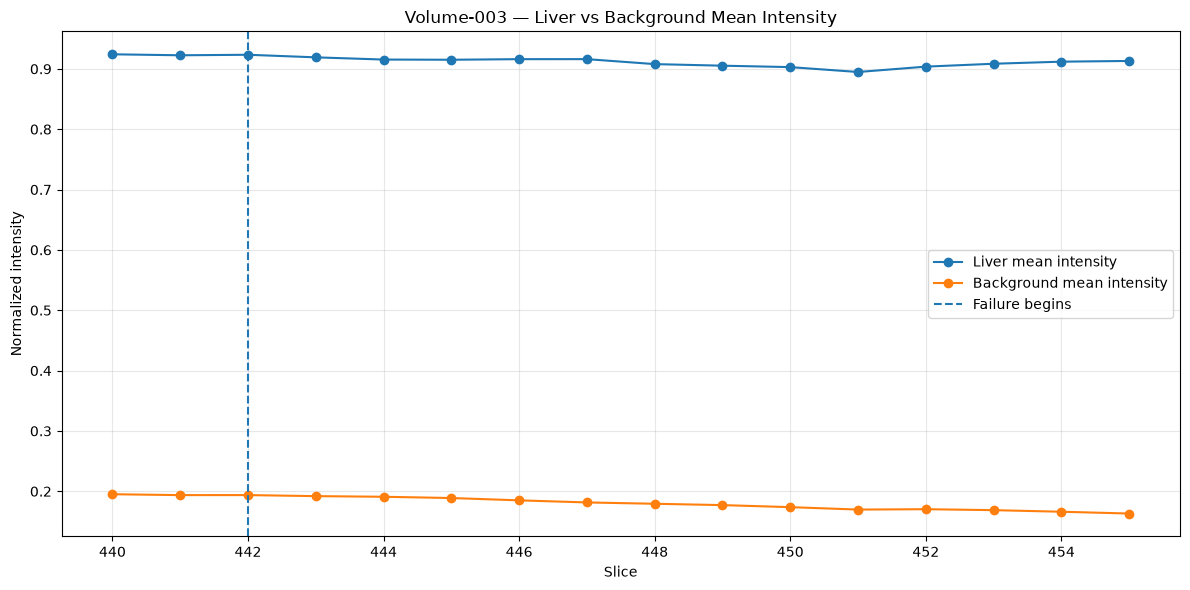

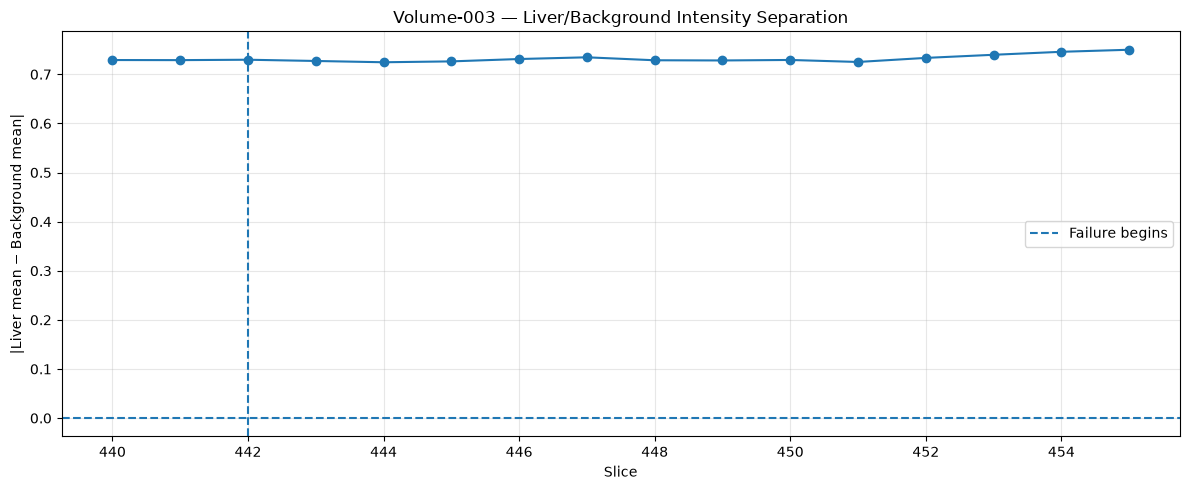


Memory cleanup completed.

STEP 7E COMPLETE


In [14]:
# ============================================================
# STEP 7E — LIVER vs BACKGROUND INTENSITY ANALYSIS
# Volume-003, slices 440–455
# ============================================================

import gc
import re
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

BASE_DIR = Path("/mnt/c/liverCTSegmentation")

ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"

TEST_CSV = (
    ANALYSIS_DIR /
    "baseline_unet_test_per_slice_metrics.csv"
)

VOLUME_ID = "Volume-003"

START_SLICE = 440
END_SLICE = 455

print("=" * 70)
print("STEP 7E — LIVER vs BACKGROUND INTENSITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD TEST CSV
# ------------------------------------------------------------

df = pd.read_csv(TEST_CSV)

def extract_volume_id(path):
    name = Path(str(path)).name

    match = re.search(
        r"(Volume-\d+)",
        name,
        re.IGNORECASE
    )

    return match.group(1) if match else "Unknown"


def extract_slice_id(path):
    name = Path(str(path)).name

    match = re.search(
        r"Volume-\d+-(\d+)",
        name,
        re.IGNORECASE
    )

    return int(match.group(1)) if match else -1


df["volume_id"] = df["image_path"].apply(
    extract_volume_id
)

df["slice_id"] = df["image_path"].apply(
    extract_slice_id
)

selected = (
    df[
        (df["volume_id"] == VOLUME_ID) &
        (df["slice_id"] >= START_SLICE) &
        (df["slice_id"] <= END_SLICE)
    ]
    .sort_values("slice_id")
    .reset_index(drop=True)
)

print(
    f"\nSelected slices: {len(selected)}"
)

# ------------------------------------------------------------
# 2. LOAD IMAGE + MASK
# ------------------------------------------------------------

images = []
masks = []

for _, row in selected.iterrows():

    image = tf.io.read_file(
        str(row["image_path"])
    )

    image = tf.image.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [128, 128],
        method=tf.image.ResizeMethod.BILINEAR
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    mask = tf.io.read_file(
        str(row["mask_path"])
    )

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.image.resize(
        mask,
        [128, 128],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    mask = tf.cast(
        mask > 127,
        tf.float32
    )

    images.append(
        image.numpy()[:, :, 0]
    )

    masks.append(
        mask.numpy()[:, :, 0]
    )

images = np.asarray(
    images,
    dtype=np.float32
)

masks = np.asarray(
    masks,
    dtype=np.float32
)

# ------------------------------------------------------------
# 3. COMPUTE LIVER/BACKGROUND STATISTICS
# ------------------------------------------------------------

rows = []

for i, row in selected.iterrows():

    image = images[i]
    mask = masks[i] > 0.5

    liver_pixels = image[mask]
    background_pixels = image[~mask]

    liver_mean = float(
        liver_pixels.mean()
    )

    liver_std = float(
        liver_pixels.std()
    )

    liver_median = float(
        np.median(liver_pixels)
    )

    background_mean = float(
        background_pixels.mean()
    )

    background_std = float(
        background_pixels.std()
    )

    background_median = float(
        np.median(background_pixels)
    )

    # Simple mean-intensity contrast
    mean_difference = (
        liver_mean - background_mean
    )

    absolute_difference = abs(
        mean_difference
    )

    # Pooled standard deviation
    pooled_std = np.sqrt(
        (
            liver_std ** 2 +
            background_std ** 2
        ) / 2
    )

    # Simple standardized separation
    effect_size = (
        mean_difference / pooled_std
        if pooled_std > 0
        else 0
    )

    rows.append({

        "slice": int(row["slice_id"]),

        "gt_area": int(row["gt_area"]),

        "dice": float(row["dice"]),

        "liver_mean": liver_mean,

        "liver_std": liver_std,

        "liver_median": liver_median,

        "background_mean": background_mean,

        "background_std": background_std,

        "background_median": background_median,

        "mean_difference": mean_difference,

        "absolute_difference": absolute_difference,

        "effect_size": effect_size
    })

contrast_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LIVER vs BACKGROUND INTENSITY")
print("=" * 70)

display(
    contrast_df.round(4)
)

# ------------------------------------------------------------
# 5. CRITICAL SLICES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CRITICAL TRANSITION")
print("=" * 70)

display(
    contrast_df[
        contrast_df["slice"].between(440, 445)
    ].round(4)
)

# ------------------------------------------------------------
# 6. SAVE CSV
# ------------------------------------------------------------

OUTPUT_CSV = (
    ANALYSIS_DIR /
    "Volume-003_440-455_liver_background_contrast.csv"
)

contrast_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print(
    f"\nSaved:\n{OUTPUT_CSV}"
)

# ------------------------------------------------------------
# 7. PLOT LIVER VS BACKGROUND MEAN
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    contrast_df["slice"],
    contrast_df["liver_mean"],
    marker="o",
    label="Liver mean intensity"
)

plt.plot(
    contrast_df["slice"],
    contrast_df["background_mean"],
    marker="o",
    label="Background mean intensity"
)

plt.axvline(
    442,
    linestyle="--",
    label="Failure begins"
)

plt.xlabel("Slice")
plt.ylabel("Normalized intensity")

plt.title(
    "Volume-003 — Liver vs Background Mean Intensity"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

PLOT1 = (
    ANALYSIS_DIR /
    "Volume-003_440-455_liver_background_mean.png"
)

plt.savefig(
    PLOT1,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. PLOT INTENSITY SEPARATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    contrast_df["slice"],
    contrast_df["absolute_difference"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    442,
    linestyle="--",
    label="Failure begins"
)

plt.xlabel("Slice")
plt.ylabel(
    "|Liver mean − Background mean|"
)

plt.title(
    "Volume-003 — Liver/Background Intensity Separation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

PLOT2 = (
    ANALYSIS_DIR /
    "Volume-003_440-455_intensity_separation.png"
)

plt.savefig(
    PLOT2,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. CLEANUP
# ------------------------------------------------------------

del images
del masks

gc.collect()

print("\nMemory cleanup completed.")

print("\n" + "=" * 70)
print("STEP 7E COMPLETE")
print("=" * 70)